<a href="https://colab.research.google.com/github/codeKrantz/AI-2010-FINAL-Project/blob/main/NCAA_Tournament_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NCAA March Madness AI 2010 Final Project
References:
* Using data from Kaggle: https://www.kaggle.com/competitions/march-machine-learning-mania-2026/overview
* Basketball 4 factors Stats: https://www.basketball-reference.com/about/factors.html?&cf=1987
* Brier Score loss function: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html
* sklearn LogisticRegression documentation: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
* This notebook requires a KAGGLE_USERNAME and KAGGLE_KEY from secrets if the validation cell is ran


In [2]:
#@title Kaggle Username and API Key Validation
#this cell is used for crediential checking
from google.colab import userdata

u = userdata.get("KAGGLE_USERNAME")
k = userdata.get("KAGGLE_KEY")
print(repr(u))                       # should be your Kaggle username
print(len(k), k != k.strip())        # key length, and whether it has stray whitespace/newline

'conradkrantz'
39 True


In [3]:
#@title Kaggle Login
import kagglehub
kagglehub.login()

In [4]:
#@title Data Importing from Kaggle
import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

import kagglehub
import pandas as pd

path = kagglehub.competition_download("march-machine-learning-mania-2026")

# See what's there
files = sorted(os.listdir(path))
print(files)

# Load the men's files (they start with "M"); swap to "W" for women's
men = {
    f.replace(".csv", ""): pd.read_csv(os.path.join(path, f), encoding="latin-1")
    for f in files
    if f.startswith("M") and f.endswith(".csv")
}

for name, df in men.items():
    print(name, df.shape)

100%|██████████| 34.8M/34.8M [00:01<00:00, 20.7MB/s]

Extracting files...


['Cities.csv', 'Conferences.csv', 'MConferenceTourneyGames.csv', 'MGameCities.csv', 'MMasseyOrdinals.csv', 'MNCAATourneyCompactResults.csv', 'MNCAATourneyDetailedResults.csv', 'MNCAATourneySeedRoundSlots.csv', 'MNCAATourneySeeds.csv', 'MNCAATourneySlots.csv', 'MRegularSeasonCompactResults.csv', 'MRegularSeasonDetailedResults.csv', 'MSeasons.csv', 'MSecondaryTourneyCompactResults.csv', 'MSecondaryTourneyTeams.csv', 'MTeamCoaches.csv', 'MTeamConferences.csv', 'MTeamSpellings.csv', 'MTeams.csv', 'SampleSubmissionStage1.csv', 'SampleSubmissionStage2.csv', 'WConferenceTourneyGames.csv', 'WGameCities.csv', 'WNCAATourneyCompactResults.csv', 'WNCAATourneyDetailedResults.csv', 'WNCAATourneySeeds.csv', 'WNCAATourneySlots.csv', 'WRegularSeasonCompactResults.csv', 'WRegularSeasonDetailedResults.csv', 'WSeasons.csv', 'WSecondaryTourneyCompactResults.csv', 'WSecondaryTourneyTeams.csv', 'WTeamConferences.csv', 'WTeamSpellings.csv', 'WTeams.csv']
MConferenceTourneyGames (7093, 5)
MGameCities (92438, 6

In [5]:
print(path)

/root/.cache/kagglehub/competitions/march-machine-learning-mania-2026


In [6]:
import pandas as pd
df = pd.read_csv(os.path.join(path, "MRegularSeasonDetailedResults.csv"))

In [7]:
df

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT,WFGM,WFGA,...,LFGA3,LFTM,LFTA,LOR,LDR,LAst,LTO,LStl,LBlk,LPF
0,2003,10,1104,68,1328,62,N,0,27,58,...,10,16,22,10,22,8,18,9,2,20
1,2003,10,1272,70,1393,63,N,0,26,62,...,24,9,20,20,25,7,12,8,6,16
2,2003,11,1266,73,1437,61,N,0,24,58,...,26,14,23,31,22,9,12,2,5,23
3,2003,11,1296,56,1457,50,N,0,18,38,...,22,8,15,17,20,9,19,4,3,23
4,2003,11,1400,77,1208,71,N,0,30,61,...,16,17,27,21,15,12,10,7,1,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124524,2026,132,1335,88,1463,84,N,1,29,64,...,24,13,17,17,24,23,9,9,4,16
124525,2026,132,1345,80,1276,72,N,0,30,57,...,24,5,6,11,22,15,7,2,3,18
124526,2026,132,1378,70,1455,55,N,0,23,61,...,19,13,20,12,27,8,14,7,7,19
124527,2026,132,1433,70,1173,62,N,0,23,57,...,21,9,17,8,31,16,11,3,4,18


## Data Cleaning

In [8]:
#@title Load the data files used by the model
import os
import pandas as pd

# `path` is set by the Kaggle download cell above.
# Only the 4 files the models need are loaded here.
FILES = {
    "rs":      "MRegularSeasonDetailedResults.csv",  # features: regular-season box scores (2003+)
    "tourney": "MNCAATourneyDetailedResults.csv",    # labels: who won each NCAA tournament game
    "seeds":   "MNCAATourneySeeds.csv",              # seed-only baseline model
    "teams":   "MTeams.csv",                         # TeamID -> school name for readable output
}

missing = [f for f in FILES.values() if not os.path.exists(os.path.join(path, f))]
assert not missing, f"Missing files in {path}: {missing}"

def load(key):
    return pd.read_csv(os.path.join(path, FILES[key]), encoding="latin-1")

rs      = load("rs")
tourney = load("tourney")
seeds   = load("seeds")
teams   = load("teams")

# Summary of what was loaded
summary = pd.DataFrame([
    {
        "variable": name,
        "file": FILES[name],
        "rows": len(d),
        "columns": d.shape[1],
        "seasons": f"{d.Season.min()}-{d.Season.max()}" if "Season" in d else "-",
    }
    for name, d in {"rs": rs, "tourney": tourney, "seeds": seeds, "teams": teams}.items()
])
print(summary.to_string(index=False))

variable                              file   rows  columns   seasons
      rs MRegularSeasonDetailedResults.csv 124529       34 2003-2026
 tourney   MNCAATourneyDetailedResults.csv   1449       34 2003-2025
   seeds             MNCAATourneySeeds.csv   2694        3 1985-2026
   teams                        MTeams.csv    381        4         -


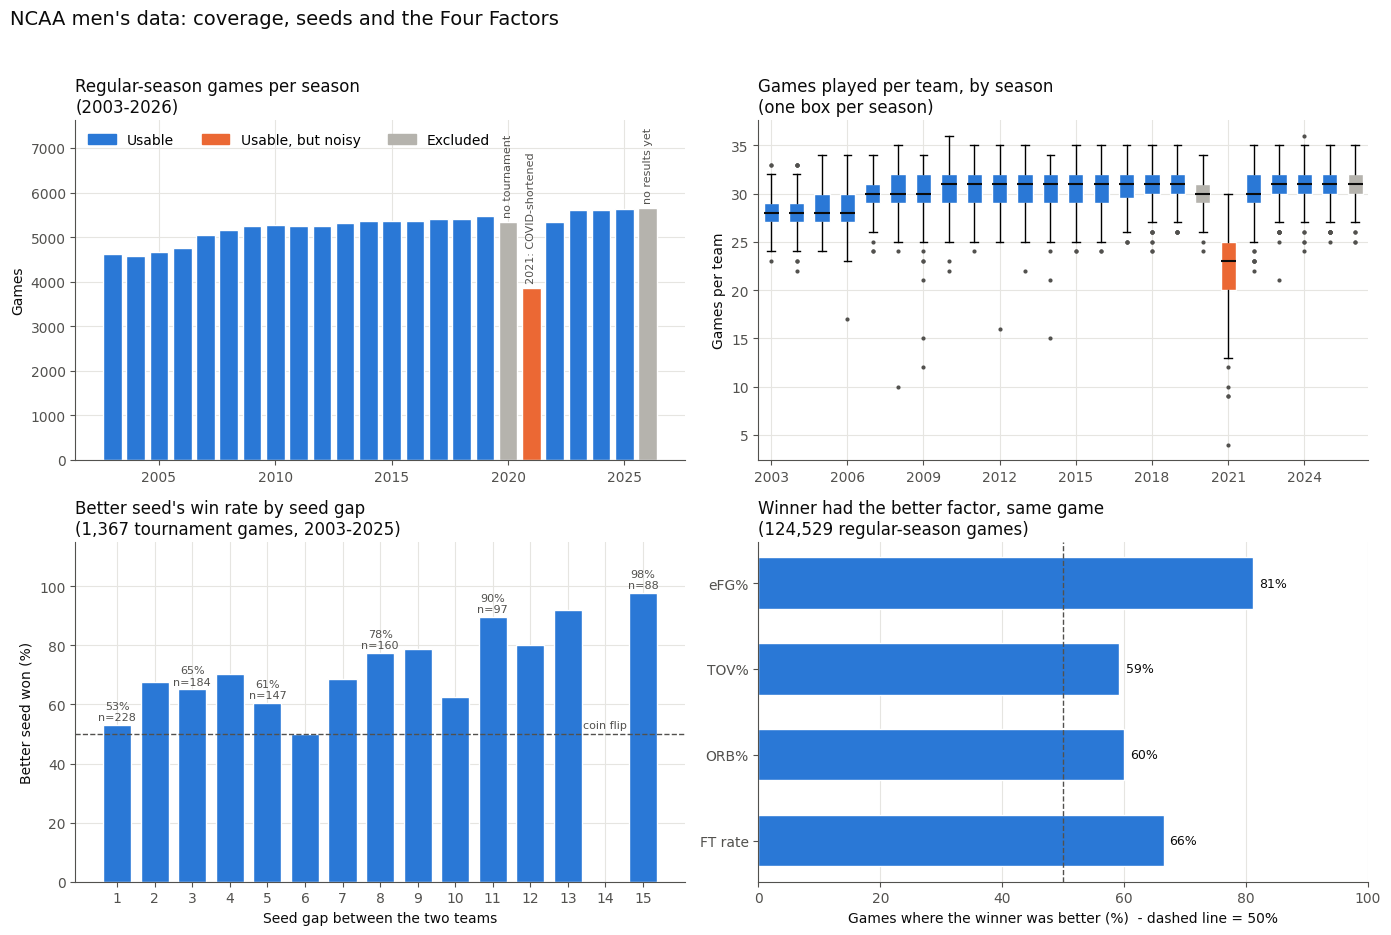

In [9]:
#@title Visualize the loaded data (exclude 2020 and acknowledge the reduced data from 2021 due to Covid)
import matplotlib.pyplot as plt

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

# Seasons that can't be used for training/testing
EXCLUDED = {2020: "no tournament", 2026: "no results yet"}

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
fig.suptitle("NCAA men's data: coverage, seeds and the Four Factors", fontsize=14, x=0.01, ha="left", color=INK)

# 1. Regular-season games per season ------------------------------------
ax = axes[0, 0]
per_season = rs.groupby("Season").size()
colors = [GRAY if s in EXCLUDED else (ORANGE if s == 2021 else BLUE) for s in per_season.index]
ax.bar(per_season.index, per_season.values, color=colors, width=0.8, edgecolor="white", linewidth=1)
for s, why in EXCLUDED.items():
    ax.annotate(why, (s, per_season[s]), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8, color=MUTED, rotation=90, va="bottom")
ax.annotate("2021: COVID-shortened", (2021, per_season[2021]), xytext=(0, 4),
            textcoords="offset points", ha="center", fontsize=8, color=MUTED, rotation=90, va="bottom")
ax.set_title("Regular-season games per season\n(2003-2026)", loc="left", color=INK)
ax.set_ylabel("Games")
ax.set_ylim(0, per_season.max() * 1.35)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE, GRAY)],
          labels=["Usable", "Usable, but noisy", "Excluded"], frameon=False, loc="upper left", ncol=3)

# 2. Games per team per season (shows how thin 2021 is) -----------------
ax = axes[0, 1]
long = pd.concat([rs[["Season", "WTeamID"]].rename(columns={"WTeamID": "TeamID"}),
                  rs[["Season", "LTeamID"]].rename(columns={"LTeamID": "TeamID"})])
gp = long.groupby(["Season", "TeamID"]).size().rename("games").reset_index()
seasons = sorted(gp.Season.unique())
bp = ax.boxplot([gp.loc[gp.Season == s, "games"] for s in seasons], positions=seasons,
                widths=0.6, patch_artist=True, showfliers=True,
                flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none"),
                medianprops=dict(color=INK, linewidth=1.5))
for patch, s in zip(bp["boxes"], seasons):
    patch.set_facecolor(GRAY if s in EXCLUDED else (ORANGE if s == 2021 else BLUE))
    patch.set_edgecolor("white")
ax.set_title("Games played per team, by season\n(one box per season)", loc="left", color=INK)
ax.set_ylabel("Games per team")
ax.set_xticks(seasons[::3], labels=[str(x) for x in seasons[::3]])

# 3. Higher seed's win rate by seed gap (seed-only baseline) ------------
ax = axes[1, 0]
s = seeds.assign(SeedNum=seeds.Seed.str[1:3].astype(int))[["Season", "TeamID", "SeedNum"]]
t = (tourney.merge(s.rename(columns={"TeamID": "WTeamID", "SeedNum": "WSeed"}), on=["Season", "WTeamID"])
            .merge(s.rename(columns={"TeamID": "LTeamID", "SeedNum": "LSeed"}), on=["Season", "LTeamID"]))
t["gap"] = (t.WSeed - t.LSeed).abs()
t = t[t.gap > 0]                                   # same-seed games (mostly First Four) have no favorite
t["fav_won"] = t.WSeed < t.LSeed
by_gap = t.groupby("gap").fav_won.agg(["mean", "size"])
ax.bar(by_gap.index, by_gap["mean"] * 100, color=BLUE, width=0.75, edgecolor="white", linewidth=1)
ax.axhline(50, color=MUTED, linewidth=1, linestyle="--")
ax.text(14, 51.5, "coin flip", fontsize=8, color=MUTED, ha="center", va="bottom")
for g, row in by_gap.iterrows():
    if g in (1, 3, 5, 8, 11, 15):
        ax.text(g, row["mean"] * 100 + 1.5, f"{row['mean']:.0%}\nn={int(row['size'])}",
                ha="center", fontsize=8, color=MUTED)
ax.set_title(f"Better seed's win rate by seed gap\n({len(t):,} tournament games, 2003-2025)", loc="left", color=INK)
ax.set_xlabel("Seed gap between the two teams")
ax.set_ylabel("Better seed won (%)")
ax.set_ylim(0, 115)
ax.set_xticks(range(1, 16))

# 4. How often the winner had the better Four Factor ---------------------
ax = axes[1, 1]
def factors(p, o):
    return pd.DataFrame({
        "eFG%":     (rs[p+"FGM"] + 0.5 * rs[p+"FGM3"]) / rs[p+"FGA"],
        "TOV%":     rs[p+"TO"] / (rs[p+"FGA"] + 0.44 * rs[p+"FTA"] + rs[p+"TO"]),
        "ORB%":     rs[p+"OR"] / (rs[p+"OR"] + rs[o+"DR"]),
        "FT rate":  rs[p+"FTA"] / rs[p+"FGA"],
    })
w, l = factors("W", "L"), factors("L", "W")
better = {
    "eFG%":    (w["eFG%"] > l["eFG%"]).mean(),
    "TOV%":    (w["TOV%"] < l["TOV%"]).mean(),     # fewer turnovers is better
    "ORB%":    (w["ORB%"] > l["ORB%"]).mean(),
    "FT rate": (w["FT rate"] > l["FT rate"]).mean(),
}
names, vals = list(better), [v * 100 for v in better.values()]
bars = ax.barh(names[::-1], vals[::-1], color=BLUE, height=0.6, edgecolor="white", linewidth=1)
ax.axvline(50, color=MUTED, linewidth=1, linestyle="--")
for b, v in zip(bars, vals[::-1]):
    ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 100)
ax.set_title(f"Winner had the better factor, same game\n({len(rs):,} regular-season games)",
             loc="left", color=INK)
ax.set_xlabel("Games where the winner was better (%)  - dashed line = 50%")
ax.grid(axis="y", visible=False)

fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

In [10]:
#@title Validate the loaded data
# Runs every check, prints a pass/fail table, then stops the notebook if a
# hard check failed. WARN rows are known quirks that the clean cell handles.
results = []

def check(file, name, bad_count, level="FAIL", detail=""):
    """bad_count = number of rows that break the rule (0 means it passes)."""
    status = "PASS" if bad_count == 0 else level
    results.append({"file": file, "check": name, "bad rows": int(bad_count),
                    "status": status, "detail": detail if bad_count else ""})

# ---------- Box-score checks (same rules for regular season and tournament) ----------
for label, g in [("rs", rs), ("tourney", tourney)]:
    check(label, "No missing values", g.isna().sum().sum())
    check(label, "No duplicate games",
          g.duplicated(["Season", "DayNum", "WTeamID", "LTeamID"]).sum())
    check(label, "No negative stats", (g.select_dtypes("number") < 0).sum().sum())
    check(label, "Winner outscored loser", (g.WScore <= g.LScore).sum())
    check(label, "A team never plays itself", (g.WTeamID == g.LTeamID).sum())
    check(label, "WLoc is H, A or N", (~g.WLoc.isin(["H", "A", "N"])).sum())

    for p, o in [("W", "L"), ("L", "W")]:
        side = "winner" if p == "W" else "loser"
        check(label, f"{side}: makes <= attempts (FG, 3PT, FT)",
              ((g[p+"FGM"] > g[p+"FGA"]) | (g[p+"FGM3"] > g[p+"FGA3"]) | (g[p+"FTM"] > g[p+"FTA"])).sum())
        check(label, f"{side}: 3PT makes/attempts <= all FG makes/attempts",
              ((g[p+"FGM3"] > g[p+"FGM"]) | (g[p+"FGA3"] > g[p+"FGA"])).sum())
        check(label, f"{side}: score = 2*FGM + FGM3 + FTM",
              (2 * g[p+"FGM"] + g[p+"FGM3"] + g[p+"FTM"] != g[p+"Score"]).sum())
        # Denominators used by the Four Factors must never be zero
        check(label, f"{side}: Four Factors denominators > 0",
              ((g[p+"FGA"] == 0) | (g[p+"OR"] + g[o+"DR"] == 0)).sum())

    ids = pd.concat([g.WTeamID, g.LTeamID])
    check(label, "Every TeamID exists in MTeams", (~ids.isin(teams.TeamID)).sum())

    # A team should play at most one game per day
    long = pd.concat([g[["Season", "DayNum", "WTeamID"]].rename(columns={"WTeamID": "TeamID"}),
                      g[["Season", "DayNum", "LTeamID"]].rename(columns={"LTeamID": "TeamID"})])
    dup_day = long[long.duplicated(keep=False)]
    check(label, "Team plays at most once per day", dup_day.duplicated().sum(), level="WARN",
          detail=", ".join(f"{r.Season} day {r.DayNum} team {r.TeamID}"
                           for r in dup_day.drop_duplicates().itertuples()))

# ---------- File-specific checks ----------
check("rs", "Regular season ends by DayNum 132", (rs.DayNum > 132).sum())
check("tourney", "Tournament games start at DayNum 134", (tourney.DayNum < 134).sum())
check("tourney", "All tournament games on a neutral court", (tourney.WLoc != "N").sum())

missing_seasons = sorted(set(range(2003, 2026)) - set(tourney.Season))
check("tourney", "A tournament every season 2003-2025", len(missing_seasons), level="WARN",
      detail=f"missing: {missing_seasons}")

check("seeds", "Seed format is region + 2 digits (+ a/b)",
      (~seeds.Seed.str.match(r"^[WXYZ]\d{2}[ab]?$")).sum())
check("seeds", "Each team seeded at most once per season",
      seeds.duplicated(["Season", "TeamID"]).sum())
check("seeds", "Every seeded TeamID exists in MTeams", (~seeds.TeamID.isin(teams.TeamID)).sum())
field = seeds.groupby("Season").size()
check("seeds", "Field size is 64, 65 or 68 teams", (~field.isin([64, 65, 68])).sum())

check("teams", "TeamIDs are unique", teams.TeamID.duplicated().sum())
check("teams", "No missing team names", teams.TeamName.isna().sum())

# ---------- Cross-file checks ----------
seed_keys = set(zip(seeds.Season, seeds.TeamID))
t_keys = list(zip(tourney.Season, tourney.WTeamID)) + list(zip(tourney.Season, tourney.LTeamID))
check("tourney+seeds", "Every tournament team has a seed",
      sum(k not in seed_keys for k in t_keys))

games_per_team = (pd.concat([rs[["Season", "WTeamID"]].rename(columns={"WTeamID": "TeamID"}),
                             rs[["Season", "LTeamID"]].rename(columns={"LTeamID": "TeamID"})])
                    .groupby(["Season", "TeamID"]).size())
seeded = seeds[seeds.Season >= 2003].set_index(["Season", "TeamID"]).index
n_games = games_per_team.reindex(seeded)
check("seeds+rs", "Every seeded team has regular-season games", n_games.isna().sum())
thin = n_games[n_games < 20]
check("seeds+rs", "Seeded teams played 20+ games", len(thin), level="WARN",
      detail=", ".join(f"{s} team {t}: {int(n)}" for (s, t), n in thin.items()))

# ---------- Report ----------
report = pd.DataFrame(results)
pd.set_option("display.max_colwidth", 80)
print(report.to_string(index=False))

counts = report.status.value_counts()
print(f"\n{counts.get('PASS', 0)} passed, {counts.get('WARN', 0)} warnings, {counts.get('FAIL', 0)} failed")
assert counts.get("FAIL", 0) == 0, "Data validation failed - see the FAIL rows above"
print("All hard checks passed. The data is safe to clean and model.")

         file                                               check  bad rows status                                                                         detail
           rs                                   No missing values         0   PASS                                                                               
           rs                                  No duplicate games         0   PASS                                                                               
           rs                                   No negative stats         0   PASS                                                                               
           rs                              Winner outscored loser         0   PASS                                                                               
           rs                           A team never plays itself         0   PASS                                                                               
           rs               

In [11]:
#@title Clean and filter the data
# Builds cleaned copies (rs_clean, tourney_clean, seeds_clean) and leaves the raw
# tables untouched, so this cell can be re-run safely.
log = []   # change log: one row per cleaning step

def record(step, table, before, after, reason):
    log.append({"step": step, "table": table, "rows before": before,
                "rows after": after, "rows removed": before - after, "reason": reason})

# ---- Step 1: keep only seasons that have both features and tournament labels ----
# 2003 = first season with box scores. 2020 = no tournament (COVID). 2026 = no results yet.
EXCLUDED_SEASONS = {2020: "no tournament (COVID)", 2026: "tournament results not available"}
SEASONS = [s for s in range(2003, 2026) if s not in EXCLUDED_SEASONS]

rs_clean = rs[rs.Season.isin(SEASONS)].copy()
record(1, "rs", len(rs), len(rs_clean), "drop 2020 and 2026 (no tournament labels)")

tourney_clean = tourney[tourney.Season.isin(SEASONS)].copy()
record(1, "tourney", len(tourney), len(tourney_clean), "drop 2020 and 2026 (none present)")

seeds_clean = seeds[seeds.Season.isin(SEASONS)].copy()
record(1, "seeds", len(seeds), len(seeds_clean), "keep 2003-2025 without 2020")

# ---- Step 2: parse seed strings into usable columns ----
# "X11a" -> Region "X", SeedNum 11, PlayIn True
seeds_clean["Region"]  = seeds_clean.Seed.str[0]
seeds_clean["SeedNum"] = seeds_clean.Seed.str[1:3].astype(int)
seeds_clean["PlayIn"]  = seeds_clean.Seed.str.len() == 4
record(2, "seeds", len(seeds_clean), len(seeds_clean), "added Region, SeedNum, PlayIn columns")

# ---- Step 3: drop First Four / opening-round games ----
# Identified by seed, not date: both teams share the same play-in seed (e.g. X11a vs X11b).
# Date alone misses 2021, when the First Four was played on day 136.
seed_lookup = seeds_clean.set_index(["Season", "TeamID"]).Seed

def seed_of(df, team_col):
    keys = pd.MultiIndex.from_frame(df[["Season", team_col]])
    return pd.Series(seed_lookup.reindex(keys).values, index=df.index)

w_seed, l_seed = seed_of(tourney_clean, "WTeamID"), seed_of(tourney_clean, "LTeamID")
is_first_four = (w_seed.str.len() == 4) & (w_seed.str[:3] == l_seed.str[:3])

before = len(tourney_clean)
first_four_games = tourney_clean[is_first_four]
tourney_clean = tourney_clean[~is_first_four].copy()
record(3, "tourney", before, len(tourney_clean),
       "drop First Four (same seed on both sides, so the seed model can't pick a favorite)")

# ---- Step 4: flag the COVID-shortened 2021 season (kept, not removed) ----
rs_clean["COVID2021"] = rs_clean.Season == 2021
tourney_clean["COVID2021"] = tourney_clean.Season == 2021
record(4, "rs + tourney", len(tourney_clean), len(tourney_clean),
       f"flagged 2021 ({rs_clean.COVID2021.sum():,} rs games, {tourney_clean.COVID2021.sum()} tourney games)")

# ---- Change log ----
change_log = pd.DataFrame(log)
print("CHANGE LOG")
print(change_log.to_string(index=False))

# ---- Post-cleaning checks ----
assert not rs_clean.Season.isin(EXCLUDED_SEASONS).any()
assert not tourney_clean.Season.isin(EXCLUDED_SEASONS).any()
assert len(first_four_games) == (seeds_clean.PlayIn.sum() // 2), "First Four count doesn't match play-in seeds"
assert seed_of(tourney_clean, "WTeamID").notna().all() and seed_of(tourney_clean, "LTeamID").notna().all()

games_per_season = tourney_clean.groupby("Season").size()
print(f"\nSeasons kept: {len(SEASONS)} ({SEASONS[0]}-{SEASONS[-1]}, no 2020)")
print(f"First Four games removed: {len(first_four_games)}")
print(f"Tournament games for modeling: {len(tourney_clean):,}")
print(f"Regular-season games for features: {len(rs_clean):,}")
odd = games_per_season[games_per_season != 63]
if len(odd):
    print("Seasons without 63 games:", odd.to_dict(),
          "(2021: VCU-Oregon was declared a no-contest due to COVID)")

CHANGE LOG
 step        table  rows before  rows after  rows removed                                                                             reason
    1           rs       124529      113554         10975                                          drop 2020 and 2026 (no tournament labels)
    1      tourney         1449        1449             0                                                  drop 2020 and 2026 (none present)
    1        seeds         2694        1472          1222                                                        keep 2003-2025 without 2020
    2        seeds         1472        1472             0                                              added Region, SeedNum, PlayIn columns
    3      tourney         1449        1385            64 drop First Four (same seed on both sides, so the seed model can't pick a favorite)
    4 rs + tourney         1385        1385             0                                    flagged 2021 (3,855 rs games, 62 tourney games)

S

## Feature engineering

**Goal:** turn each regular season into one profile per team, then describe each tournament matchup as the *difference* between the two teams' profiles. Only regular-season games (DayNum ≤ 132) are used to build features, so nothing from the tournament leaks into the inputs.

### Step 1: One row per team per game
The raw data stores each game as **winner vs. loser**. Averaging only winner columns would describe *winning*, not the team. So every game is split into two rows, one from each team's point of view:

| Column group | Meaning |
|---|---|
| `Team…` | the team's own box score (its offense) |
| `Opp…` | the opponent's box score in that game (what the team's defense allowed) |

### Step 2: Season totals → Four Factors
For each team and season, the box-score stats are **summed first, then turned into rates**. This weights every possession equally, so a few blowouts or slow games can't skew the result the way averaging per-game percentages would.

| Factor | Offense (team's own) | Defense (opponent's, allowed by the team) |
|---|---|---|
| **Shooting**: eFG% | (FGM + 0.5·FGM3) / FGA | opponent eFG% allowed |
| **Turnovers**: TOV% | TO / (FGA + 0.44·FTA + TO) | opponent TOV% forced |
| **Rebounding**: ORB% | OR / (OR + opponent DR) | opponent ORB% allowed |
| **Free throws**: FT rate | FTA / FGA | opponent FT rate allowed |

That gives **8 numbers per team-season**: 4 offense and 4 defense. Defense uses the *same formulas* applied to the opponent's stats, so the two sides are directly comparable.

Direction matters. Higher is better for offensive eFG%, ORB% and FT rate, but lower is better for offensive TOV%. On defense it flips: lower allowed eFG% is better, and higher forced TOV% is better. Logistic regression learns these signs on its own, so no values are flipped by hand.

### Step 3: Schedule adjustment
Raw rates flatter teams that played weak opponents. So each factor is compared with what that team's opponents usually do. For every game a team played, the opponent's season rate on the matching side is looked up, those values are averaged over the team's schedule, and the average is subtracted:

| Side | Adjusted value |
|---|---|
| Offense | team's offensive rate − average rate its opponents' **defenses allowed** |
| Defense | rate the team allowed − average rate its opponents' **offenses produced** |

A positive offensive eFG% now means "shot better than these opponents usually allow." This is a simple one-pass adjustment: the opponents' own numbers are not adjusted in turn. Because every team is measured against its own opponents, the season average of each adjusted factor lands at about 0, which is what the sanity-check table printed by the next cell shows (every value within ±0.002).

### Step 4: Season normalization (z-scores)
College basketball changes over time (more 3-pointers, fewer free throws), so the same number means something different in 2005 than in 2025. Each schedule-adjusted factor is converted to a **z-score within its season**:

> z = (team value − season average) / season standard deviation

A z of +1.0 means one standard deviation better than that season's average, which makes all 22 seasons comparable.

### Step 5: Matchup features (Team A − Team B)
Each tournament game becomes one row:
- **Team A** = the lower TeamID, **Team B** = the higher TeamID (the same convention Kaggle uses).
- **Label** = 1 if Team A won, 0 if Team B won. Ordering by TeamID instead of winner/loser keeps the labels balanced: Team A won 50.4% of the 1,385 games.
- **Features** = Team A's value − Team B's value for each input.

### Step 6: Three feature sets, one per model

| Model | Features | Count |
|---|---|---|
| **Seed-only** (baseline) | seed difference (A − B) | 1 |
| **Offense-only** | eFG%, TOV%, ORB%, FT rate differences (offense) | 4 |
| **Defense-only** | eFG%, ORB%, FT rate allowed and TOV% forced (differences) | 4 |

Offense and defense get the **same number of features built the same way**, so neither model has an advantage from having more inputs. The comparison is about which side's stats predict tournament winners better.

In [12]:
#@title Build features: Four Factors (offense & defense), season z-scores, matchups
import numpy as np
STATS = ["Score", "FGM", "FGA", "FGM3", "FGA3", "FTM", "FTA", "OR", "DR", "Ast", "TO", "Stl", "Blk", "PF"]

# ---- Step 1: one row per team per game (team's own stats + opponent's stats) ----
def team_view(df, me, opp):
    out = df[["Season", "DayNum"]].copy()
    out["TeamID"] = df[me + "TeamID"]
    out["OppID"]  = df[opp + "TeamID"]
    for s in STATS:
        out["Team" + s] = df[me + s]
        out["Opp" + s]  = df[opp + s]
    return out

team_games = pd.concat([team_view(rs_clean, "W", "L"), team_view(rs_clean, "L", "W")],
                       ignore_index=True)
assert len(team_games) == 2 * len(rs_clean)

# ---- Step 2: season totals -> Four Factors ----
SUM_COLS = [side + s for side in ("Team", "Opp") for s in STATS]
totals = team_games.groupby(["Season", "TeamID"])[SUM_COLS].sum()
totals["Games"] = team_games.groupby(["Season", "TeamID"]).size()

def four_factors(t, me, opp):
    """Four Factors for side `me` ('Team' = offense, 'Opp' = what the defense allowed)."""
    return pd.DataFrame({
        "eFG": (t[me+"FGM"] + 0.5 * t[me+"FGM3"]) / t[me+"FGA"],
        "TOV": t[me+"TO"] / (t[me+"FGA"] + 0.44 * t[me+"FTA"] + t[me+"TO"]),
        "ORB": t[me+"OR"] / (t[me+"OR"] + t[opp+"DR"]),
        "FTR": t[me+"FTA"] / t[me+"FGA"],
    }, index=t.index)

off = four_factors(totals, "Team", "Opp").add_prefix("Off_")
dfn = four_factors(totals, "Opp", "Team").add_prefix("Def_")
team_feats = pd.concat([off, dfn, totals[["Games"]]], axis=1)
FACTOR_COLS = list(off.columns) + list(dfn.columns)

# Schedule average: mean of each opponent's raw factors, one row per game played
opp = team_games[["Season", "TeamID", "OppID"]].merge(
    team_feats[FACTOR_COLS].rename_axis(["Season", "OppID"]).reset_index(),
    on=["Season", "OppID"])
sched = opp.groupby(["Season", "TeamID"])[FACTOR_COLS].mean()

for f in ["eFG", "TOV", "ORB", "FTR"]:
    team_feats["Off_" + f] -= sched["Def_" + f]   # vs. what opponents usually allow
    team_feats["Def_" + f] -= sched["Off_" + f]   # vs. what opponents usually produce

# ---- Step 3: z-score each factor within its season (all D-I teams) ----
season_mean = team_feats.groupby(level="Season")[FACTOR_COLS].transform("mean")
season_std  = team_feats.groupby(level="Season")[FACTOR_COLS].transform("std")
team_z = (team_feats[FACTOR_COLS] - season_mean) / season_std
team_z = team_z.reset_index()

# ---- Step 4: tournament matchups, Team A = lower TeamID ----
m = tourney_clean[["Season", "DayNum", "WTeamID", "LTeamID", "COVID2021"]].copy()
m["TeamA"] = m[["WTeamID", "LTeamID"]].min(axis=1)
m["TeamB"] = m[["WTeamID", "LTeamID"]].max(axis=1)
m["Label"] = (m.WTeamID == m.TeamA).astype(int)

seed_num = seeds_clean[["Season", "TeamID", "SeedNum"]]
for side in ("A", "B"):
    m = (m.merge(team_z.rename(columns={"TeamID": "Team" + side, **{c: f"{c}_{side}" for c in FACTOR_COLS}}),
                 on=["Season", "Team" + side], how="left")
          .merge(seed_num.rename(columns={"TeamID": "Team" + side, "SeedNum": "Seed_" + side}),
                 on=["Season", "Team" + side], how="left"))

# Differences (A - B)
m["SeedDiff"] = m.Seed_A - m.Seed_B
for c in FACTOR_COLS:
    m[c + "_diff"] = m[c + "_A"] - m[c + "_B"]

SEED_FEATURES = ["SeedDiff"]
OFF_FEATURES  = [c + "_diff" for c in off.columns]
DEF_FEATURES  = [c + "_diff" for c in dfn.columns]

matchups = m[["Season", "DayNum", "TeamA", "TeamB", "Label", "COVID2021",
              "Seed_A", "Seed_B"] + SEED_FEATURES + OFF_FEATURES + DEF_FEATURES]

# ---- Checks ----
assert len(matchups) == len(tourney_clean), "lost or duplicated games while merging"
assert matchups[SEED_FEATURES + OFF_FEATURES + DEF_FEATURES].notna().all().all(), "missing features"
assert team_feats[FACTOR_COLS].notna().all().all() and np.isfinite(team_feats[FACTOR_COLS]).all().all()
z_check = team_z.groupby("Season")[FACTOR_COLS].agg(["mean", "std"])
assert z_check.xs("mean", axis=1, level=1).abs().max().max() < 1e-9
assert (z_check.xs("std", axis=1, level=1) - 1).abs().max().max() < 1e-9
assert sched.notna().all().all()

# ---- Summary ----
print(f"Team-game rows: {len(team_games):,}  |  team-seasons: {len(team_feats):,}  |  matchups: {len(matchups):,}")
print(f"Label balance (Team A won): {matchups.Label.mean():.1%}")
print("\nRaw Four Factors, average across all teams (sanity check):")
print(team_feats[FACTOR_COLS].groupby(level="Season").mean().loc[[2003, 2013, 2025]].round(3).to_string())

names = teams.set_index("TeamID").TeamName
ex = matchups.iloc[-1]
print(f"\nExample row: {ex.Season} {names[ex.TeamA]} ({int(ex.Seed_A)}) vs "
      f"{names[ex.TeamB]} ({int(ex.Seed_B)}), Label={int(ex.Label)}")
print(matchups.iloc[[-1]][SEED_FEATURES + OFF_FEATURES + DEF_FEATURES].round(2).to_string(index=False))

Team-game rows: 227,108  |  team-seasons: 7,628  |  matchups: 1,385
Label balance (Team A won): 50.4%

Raw Four Factors, average across all teams (sanity check):
        Off_eFG  Off_TOV  Off_ORB  Off_FTR  Def_eFG  Def_TOV  Def_ORB  Def_FTR
Season                                                                        
2003     -0.000      0.0   -0.001   -0.001    0.001     -0.0    0.001    0.001
2013     -0.001      0.0   -0.001   -0.002    0.001     -0.0    0.001    0.002
2025     -0.001      0.0   -0.001   -0.001    0.001     -0.0    0.001    0.002

Example row: 2025 Florida (1) vs Houston (1), Label=1
 SeedDiff  Off_eFG_diff  Off_TOV_diff  Off_ORB_diff  Off_FTR_diff  Def_eFG_diff  Def_TOV_diff  Def_ORB_diff  Def_FTR_diff
        0           0.7          0.69          0.21          0.81          -0.0         -1.97          0.62         -0.93


### What the feature visuals show

**Left chart: who wins when one team has the edge?**
Each dot is the share of the 1,385 tournament games won by the team that was better in one factor during the regular season. 50% is a coin flip; the dotted line is the seed baseline (the better seed won 71.3% of the 1,367 games between different seeds).
- **Shooting** is the strongest single factor on both sides: better shooting offense won 62% and better shooting defense won 61%.
- **Turnovers and rebounding** mattered more on offense (59%, 61%) than on defense (55%, 57%).
- **Free throws** flipped: getting to the line more on offense won only 51%, barely better than a coin flip, while limiting opponents' free throws won 55%.
- Offense has the higher win rate in three of the four factors; free throws is the exception.
- No single factor beats seeds. The models test whether all four together can.

**Right chart: how related are the features?**
Each cell is the correlation between two features across 7,628 team-seasons. All values are weak to moderate (largest = 0.47, defensive eFG% with defensive ORB%), so the features don't repeat each other and logistic regression can separate their effects. Colors show statistical direction, not good vs. bad.

*These are one-factor-at-a-time previews. Small gaps can be noise; the models with leave-one-season-out testing give the real answer.*

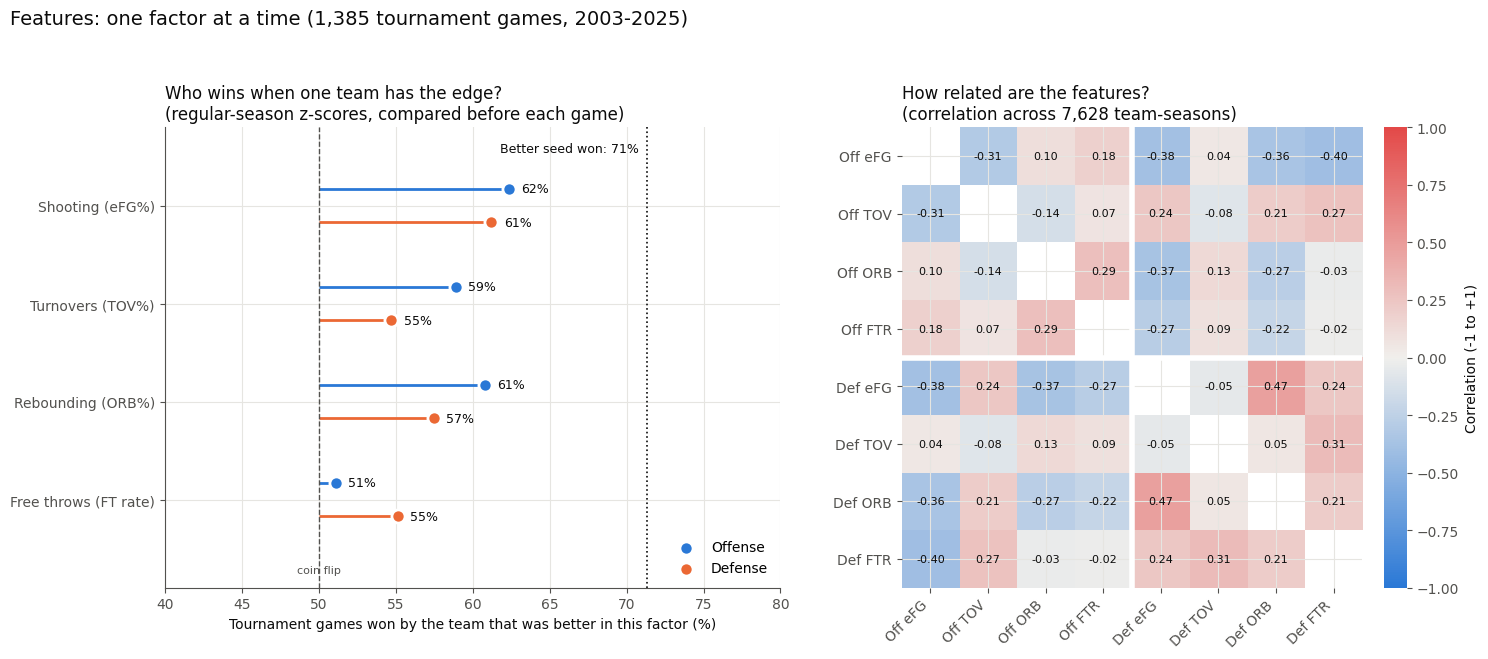

Team with the better factor won:
                       Offense %  Defense %
Shooting (eFG%)             62.4       61.2
Turnovers (TOV%)            58.9       54.7
Rebounding (ORB%)           60.8       57.5
Free throws (FT rate)       51.1       55.2
Better seed won: 71.3% (1,367 games with different seeds)


In [13]:
#@title Visualize the features
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
DIVERGING = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

FACTOR_NAMES = {"eFG": "Shooting (eFG%)", "TOV": "Turnovers (TOV%)",
                "ORB": "Rebounding (ORB%)", "FTR": "Free throws (FT rate)"}
# +1 if a HIGHER value is better for the team, -1 if LOWER is better
BETTER_IF_HIGHER = {"Off_eFG": 1, "Off_TOV": -1, "Off_ORB": 1, "Off_FTR": 1,
                    "Def_eFG": -1, "Def_TOV": 1, "Def_ORB": -1, "Def_FTR": -1}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
fig.suptitle(f"Features: one factor at a time ({len(matchups):,} tournament games, 2003-2025)",
             fontsize=14, x=0.01, ha="left", color=INK)

# ---- 1. How often the team that was better in each factor won ----
def better_team_won(col):
    edge = matchups[col + "_diff"] * BETTER_IF_HIGHER[col]   # >0 means Team A was better
    edge = edge[edge != 0]
    a_won = matchups.loc[edge.index, "Label"] == 1
    return ((edge > 0) == a_won).mean() * 100

factors = list(FACTOR_NAMES)
off_rates = [better_team_won("Off_" + f) for f in factors]
def_rates = [better_team_won("Def_" + f) for f in factors]
y = np.arange(len(factors))[::-1]
offset = 0.17
# Dot plot measured from the 50% coin-flip line (bars would need to start at 0)
for rates, color, dy, name in ((off_rates, BLUE, offset, "Offense"), (def_rates, ORANGE, -offset, "Defense")):
    ax1.hlines(y + dy, 50, rates, color=color, linewidth=2)
    ax1.scatter(rates, y + dy, s=90, color=color, zorder=3, edgecolor="white", linewidth=2, label=name)
    for yy, r in zip(y + dy, rates):
        ax1.text(r + (0.8 if r >= 50 else -0.8), yy, f"{r:.0f}%", va="center",
                 ha="left" if r >= 50 else "right", fontsize=9, color=INK)

seeded = matchups[matchups.SeedDiff != 0]
seed_rate = ((seeded.SeedDiff < 0) == (seeded.Label == 1)).mean() * 100
ax1.axvline(seed_rate, color=INK, linewidth=1.2, linestyle=":")
ax1.text(seed_rate - 0.5, len(factors) - 0.45, f"Better seed won: {seed_rate:.0f}%",
         fontsize=9, color=INK, ha="right")
ax1.axvline(50, color=MUTED, linewidth=1, linestyle="--")
ax1.text(50, -0.75, "coin flip", fontsize=8, color=MUTED, ha="center")

ax1.set_yticks(y, [FACTOR_NAMES[f] for f in factors])
ax1.set_xlim(40, 80)
ax1.set_ylim(-0.9, len(factors) - 0.2)
ax1.set_xlabel("Tournament games won by the team that was better in this factor (%)")
ax1.set_title("Who wins when one team has the edge?\n(regular-season z-scores, compared before each game)",
              loc="left", color=INK)
ax1.legend(frameon=False, loc="lower right")
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)
ax1.grid(axis="x", color="#e6e5e1")
ax1.set_axisbelow(True)

# ---- 2. Correlation between the 8 features (team-season level) ----
labels = [c.replace("Off_", "Off ").replace("Def_", "Def ") for c in FACTOR_COLS]
corr = team_z[FACTOR_COLS].corr()
shown = corr.values.copy()
np.fill_diagonal(shown, np.nan)                     # a feature vs itself is always 1.00
DIVERGING.set_bad("white")
im = ax2.imshow(shown, cmap=DIVERGING, vmin=-1, vmax=1)
ax2.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax2.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if i == j:
            continue
        v = corr.values[i, j]
        ax2.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                 color="white" if abs(v) > 0.6 else INK)
ax2.axhline(3.5, color="white", linewidth=4)
ax2.axvline(3.5, color="white", linewidth=4)
ax2.set_title(f"How related are the features?\n(correlation across {len(team_z):,} team-seasons)",
              loc="left", color=INK)
for spine in ax2.spines.values():
    spine.set_visible(False)
cb = fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
cb.set_label("Correlation (-1 to +1)")
cb.outline.set_visible(False)

fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

print("Team with the better factor won:")
print(pd.DataFrame({"Offense %": off_rates, "Defense %": def_rates},
                   index=[FACTOR_NAMES[f] for f in factors]).round(1).to_string())
print(f"Better seed won: {seed_rate:.1f}% ({len(seeded):,} games with different seeds)")

## Modeling: seed vs. offense vs. defense

**Question:** whose regular-season stats better predict NCAA tournament winners, a team's offense or its defense?

### Three models, same method
All three are **logistic regression**: they turn the matchup features into a probability that Team A wins. Only the inputs change:

| Model | Inputs (Team A − Team B) | Role |
|---|---|---|
| **Seed-only** | seed difference (1 feature) | Baseline: what the selection committee already knows |
| **Offense-only** | eFG%, TOV%, ORB%, FT rate (4 features) | Tests offense |
| **Defense-only** | eFG%, TOV%, ORB%, FT rate allowed (4 features) | Tests defense |

Offense and defense get the same number of features, built the same way, so neither has an advantage from more inputs. Features are standardized inside a pipeline, so each model learns the scaling only from its training data.

### Testing: leave-one-season-out
There are 22 seasons (2003–2025, without 2020). For each season:
1. **Train** on the other 21 seasons.
2. **Predict** every tournament game in the held-out season.

Each game is predicted by a model that never saw that season, just like predicting a new tournament. This repeats 22 times, so every one of the 1,385 games gets one out-of-sample prediction from each model.

### How the models are scored
| Metric | What it measures | Better is |
|---|---|---|
| **Accuracy** | % of games where the model picked the winner | Higher |
| **Log loss** | Quality of the probabilities; confident wrong picks are punished heavily (the Kaggle metric) | Lower |
| **Brier score** | Average squared gap between the probability and the result (0 or 1) | Lower |

A model that always predicts 50% scores 50% accuracy, a log loss of 0.693 and a Brier score of 0.25. Any useful model must beat these numbers.

### How the winner is decided
The main metric is the **Brier score**. For each season, the gap is calculated as **Defense Brier − Offense Brier**, so a positive gap means offense predicted better.

A difference counts as **real only if both** are true:
1. The **season-level bootstrap 95% interval** for the pooled gap excludes zero. Whole seasons are resampled with replacement 10,000 times, because games within the same tournament aren't independent.
2. The **same side has the better Brier score in most of the 22 seasons**.

If either condition fails, the result is reported as a **tie**.

In [14]:
#@title Train, test and compare the three models (plan: Brier + season bootstrap)
# Model choice: logistic regression.
# It beat random forest, gradient boosting and a small neural net on log loss
# for all three feature sets in a leave-one-season-out comparison. With ~1,400 games
# and 1-4 features, more complex models overfit the training seasons. Logistic
# regression also gives one readable coefficient per factor.
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

FEATURE_SETS = {"Seed": SEED_FEATURES, "Offense": OFF_FEATURES, "Defense": DEF_FEATURES}
N_BOOT, RANDOM_SEED = 10_000, 2010

def make_model():
    # Scaling lives inside the pipeline, so it is learned from training seasons only
    return make_pipeline(StandardScaler(), LogisticRegression())

# ---------- 1. Leave-one-season-out: hold out one tournament, train on the rest ----------
preds = matchups[["Season", "DayNum", "TeamA", "TeamB", "Label", "COVID2021"]].copy()
for season in sorted(matchups.Season.unique()):
    test = matchups.Season == season
    for name, cols in FEATURE_SETS.items():
        model = make_model().fit(matchups.loc[~test, cols], matchups.loc[~test, "Label"])
        preds.loc[test, "p_" + name] = model.predict_proba(matchups.loc[test, cols])[:, 1]

assert preds.filter(like="p_").notna().all().all(), "some games were never predicted"
SEASONS_TESTED = preds.Season.nunique()

# Per-game Brier score = (predicted probability - actual result)^2
for name in FEATURE_SETS:
    preds["brier_" + name] = (preds["p_" + name] - preds.Label) ** 2

# ---------- 2. Brier score for each season ----------
season_brier = preds.groupby("Season")[[f"brier_{n}" for n in FEATURE_SETS]].mean()
season_brier.columns = list(FEATURE_SETS)
season_brier["Gap (Def - Off)"] = season_brier.Defense - season_brier.Offense
season_brier["Better side"] = np.where(season_brier["Gap (Def - Off)"] > 0, "Offense",
                              np.where(season_brier["Gap (Def - Off)"] < 0, "Defense", "Tie"))
season_brier.insert(0, "Games", preds.groupby("Season").size())

print("BRIER SCORE BY HELD-OUT SEASON (lower is better)")
print(season_brier.round(4).to_string())

# ---------- 3. Pooled across seasons (main metric = Brier; others are supporting) ----------
def pooled(name):
    y, p = preds.Label, preds["p_" + name]
    return {"Brier": brier_score_loss(y, p), "Log loss": log_loss(y, p),
            "Accuracy": accuracy_score(y, p > 0.5)}

overall = pd.DataFrame({name: pooled(name) for name in FEATURE_SETS}).T
coin = np.full(len(preds), 0.5)
overall.loc["Coin flip (always 50%)"] = [brier_score_loss(preds.Label, coin),
                                         log_loss(preds.Label, coin), np.nan]
print(f"\nPOOLED ACROSS {SEASONS_TESTED} SEASONS ({len(preds):,} games)")
print(overall.round(4).to_string(na_rep="-"))

# ---------- 4. Season-level bootstrap 95% interval for the offense-vs-defense gap ----------
# Whole seasons are resampled (not single games), because games in the same
# tournament share the same trained model and aren't independent.
game_gap = preds.brier_Defense - preds.brier_Offense            # > 0 means offense was better
per_season = game_gap.groupby(preds.Season).agg(["sum", "size"])
observed_gap = per_season["sum"].sum() / per_season["size"].sum()

rng = np.random.default_rng(RANDOM_SEED)
picks = rng.integers(0, SEASONS_TESTED, size=(N_BOOT, SEASONS_TESTED))
boot_gaps = per_season["sum"].values[picks].sum(axis=1) / per_season["size"].values[picks].sum(axis=1)
ci_low, ci_high = np.percentile(boot_gaps, [2.5, 97.5])

# ---------- 5. Decision rule ----------
off_wins = (season_brier["Better side"] == "Offense").sum()
def_wins = (season_brier["Better side"] == "Defense").sum()
interval_excludes_zero = ci_low > 0 or ci_high < 0
leader = "Offense" if observed_gap > 0 else "Defense"
leader_wins = off_wins if leader == "Offense" else def_wins
majority = leader_wins > SEASONS_TESTED / 2

print("\nOFFENSE vs DEFENSE")
print(f"  Pooled Brier gap (Def - Off): {observed_gap:+.4f}   (positive = offense predicted better)")
print(f"  Season bootstrap 95% interval: [{ci_low:+.4f}, {ci_high:+.4f}]   ({N_BOOT:,} resamples)")
print(f"  Seasons won: Offense {off_wins}, Defense {def_wins} (of {SEASONS_TESTED})")
print(f"  Condition 1 - interval excludes zero:          {'PASS' if interval_excludes_zero else 'FAIL'}")
print(f"  Condition 2 - {leader} wins most seasons:      {'PASS' if majority else 'FAIL'} ({leader_wins}/{SEASONS_TESTED})")

if interval_excludes_zero and majority:
    verdict = f"{leader}'s stats predict tournament winners better (difference is real)."
else:
    verdict = "TIE: the offense-vs-defense difference is not reliable under the decision rule."
print(f"\nVERDICT: {verdict}")

BRIER SCORE BY HELD-OUT SEASON (lower is better)
        Games    Seed  Offense  Defense  Gap (Def - Off) Better side
Season                                                              
2003       63  0.1762   0.1886   0.2355           0.0470     Offense
2004       63  0.1716   0.2044   0.2025          -0.0018     Defense
2005       63  0.1852   0.2119   0.2000          -0.0119     Defense
2006       63  0.2043   0.1975   0.2207           0.0232     Offense
2007       63  0.1419   0.1802   0.1946           0.0144     Offense
2008       63  0.1771   0.1994   0.1880          -0.0114     Defense
2009       63  0.1665   0.1865   0.2130           0.0266     Offense
2010       63  0.2011   0.2091   0.2174           0.0082     Offense
2011       63  0.2111   0.2240   0.2435           0.0195     Offense
2012       63  0.1936   0.2284   0.1972          -0.0313     Defense
2013       63  0.2113   0.2094   0.2187           0.0093     Offense
2014       63  0.2204   0.2035   0.2153           0.01

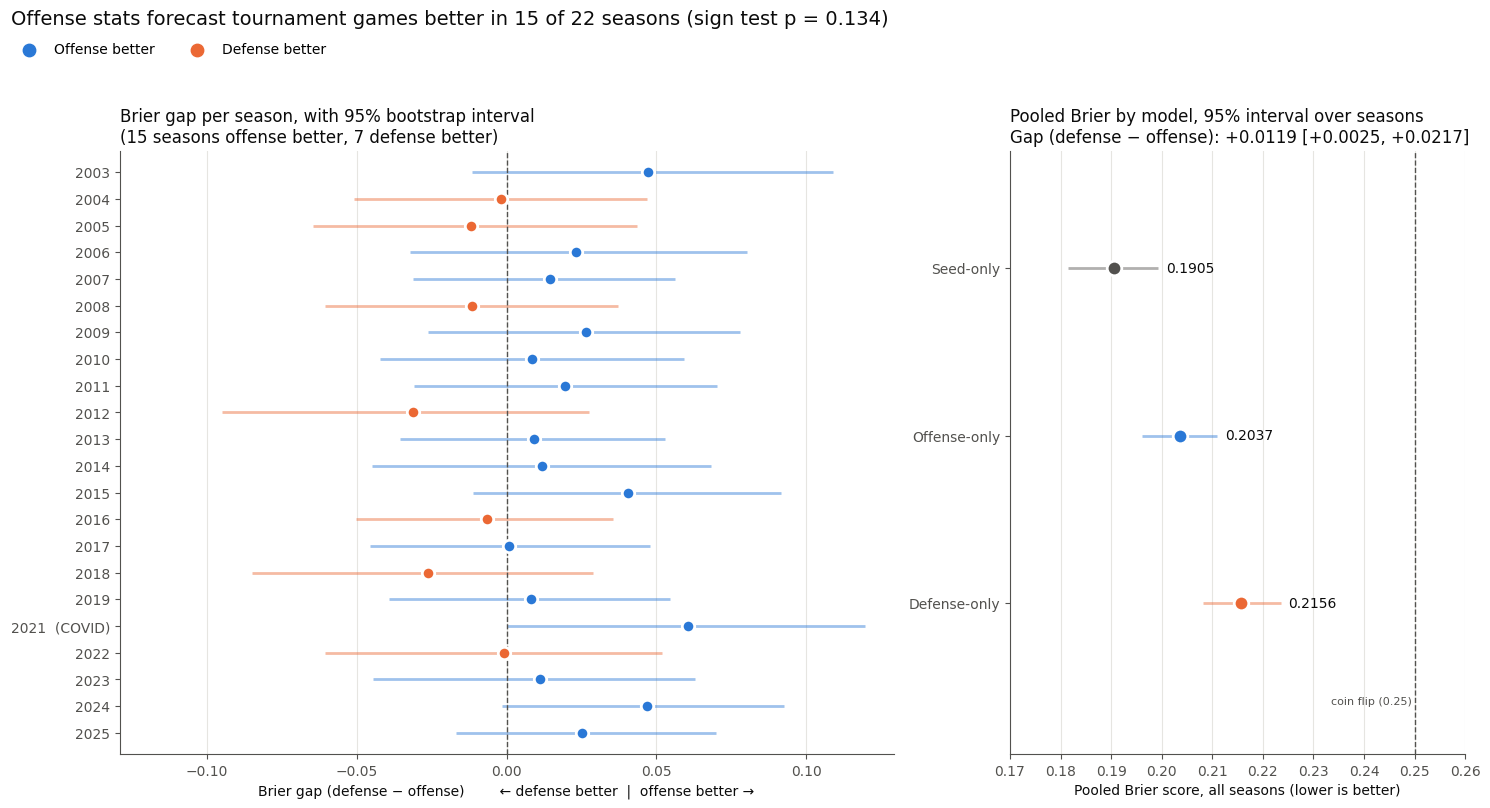

 Season  games  brier_off  brier_def     gap      lo     hi  winner
   2003     63     0.1886     0.2357  0.0471 -0.0116 0.1088 offense
   2004     63     0.2044     0.2025 -0.0019 -0.0510 0.0470 defense
   2005     63     0.2119     0.1999 -0.0120 -0.0647 0.0436 defense
   2006     63     0.1975     0.2207  0.0232 -0.0324 0.0802 offense
   2007     63     0.1801     0.1945  0.0145 -0.0313 0.0561 offense
   2008     63     0.1994     0.1880 -0.0114 -0.0608 0.0373 defense
   2009     63     0.1864     0.2130  0.0266 -0.0261 0.0779 offense
   2010     63     0.2091     0.2174  0.0083 -0.0424 0.0591 offense
   2011     63     0.2241     0.2436  0.0195 -0.0309 0.0704 offense
   2012     63     0.2285     0.1972 -0.0313 -0.0949 0.0277 defense
   2013     63     0.2094     0.2187  0.0092 -0.0356 0.0530 offense
   2014     63     0.2035     0.2154  0.0119 -0.0450 0.0681 offense
   2015     63     0.1659     0.2063  0.0404 -0.0114 0.0917 offense
   2016     63     0.2144     0.2080 -0.0064 -0.

In [15]:
#@title Results: Brier gap by season (offense vs defense) + pooled Brier by model
# Self-contained: needs only `matchups`, SEED_FEATURES, OFF_FEATURES, DEF_FEATURES
# from the feature cell. If your modeling cell already produced out-of-sample
# probabilities, put them in `oos` (columns Season, Label, p_seed, p_off, p_def)
# and skip the leave-one-season-out block.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
RNG = np.random.default_rng(2010)
N_BOOT = 2000

MODELS = {"seed": SEED_FEATURES, "off": OFF_FEATURES, "def": DEF_FEATURES}
MODEL_NAMES = {"seed": "Seed-only", "off": "Offense-only", "def": "Defense-only"}
MODEL_COLORS = {"seed": MUTED, "off": BLUE, "def": ORANGE}

# ---- 1. Leave-one-season-out predictions (every game predicted by a model that never saw its season) ----
oos = matchups[["Season", "Label"]].copy()
for key, feats in MODELS.items():
    oos["p_" + key] = np.nan
    for season in sorted(matchups.Season.unique()):
        train, test = matchups.Season != season, matchups.Season == season
        clf = LogisticRegression(max_iter=1000).fit(matchups.loc[train, feats], matchups.loc[train, "Label"])
        oos.loc[test, "p_" + key] = clf.predict_proba(matchups.loc[test, feats])[:, 1]

for key in MODELS:                                   # squared error per game; Brier = its mean
    oos["se_" + key] = (oos["p_" + key] - oos.Label) ** 2
oos["gap"] = oos.se_def - oos.se_off                 # > 0 means offense forecast better

# ---- 2. Per-season gap with a bootstrap interval (resample games within the season) ----
rows = []
for season, g in oos.groupby("Season"):
    d = g.gap.to_numpy()
    boots = RNG.choice(d, size=(N_BOOT, len(d)), replace=True).mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    rows.append({"Season": season, "games": len(d), "brier_off": g.se_off.mean(),
                 "brier_def": g.se_def.mean(), "gap": d.mean(), "lo": lo, "hi": hi})
by_season = pd.DataFrame(rows)

off_wins = int((by_season.gap > 0).sum())
def_wins = int((by_season.gap < 0).sum())
sign_p = binomtest(off_wins, off_wins + def_wins, 0.5).pvalue

# ---- 3. Pooled Brier per model, bootstrap over whole seasons (keeps each season's games together) ----
seasons = by_season.Season.to_numpy()
season_sums = oos.groupby("Season")[["se_seed", "se_off", "se_def", "gap"]].sum().loc[seasons]
season_n = oos.groupby("Season").size().loc[seasons].to_numpy()
idx = RNG.integers(0, len(seasons), size=(N_BOOT, len(seasons)))
boot_pooled = {c: season_sums[c].to_numpy()[idx].sum(axis=1) / season_n[idx].sum(axis=1)
               for c in season_sums.columns}
pooled = pd.DataFrame({
    "model": [MODEL_NAMES[k] for k in MODELS],
    "brier": [oos["se_" + k].mean() for k in MODELS],
    "lo": [np.percentile(boot_pooled["se_" + k], 2.5) for k in MODELS],
    "hi": [np.percentile(boot_pooled["se_" + k], 97.5) for k in MODELS],
}, index=list(MODELS))
pooled_gap = oos.gap.mean()
pooled_gap_lo, pooled_gap_hi = np.percentile(boot_pooled["gap"], [2.5, 97.5])

# ---- 4. Figure ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8.2), gridspec_kw={"width_ratios": [1.7, 1]})
fig.suptitle(f"Offense stats forecast tournament games better in {off_wins} of {off_wins + def_wins} seasons "
             f"(sign test p = {sign_p:.3f})", fontsize=14, x=0.01, ha="left", color=INK)

# Left: one row per season, newest at the bottom
y = np.arange(len(by_season))[::-1]
for yy, r in zip(y, by_season.itertuples()):
    color = BLUE if r.gap > 0 else ORANGE
    ax1.hlines(yy, r.lo, r.hi, color=color, linewidth=2, alpha=0.45)
    ax1.scatter(r.gap, yy, s=80, color=color, edgecolor="white", linewidth=2, zorder=3)
ax1.axvline(0, color=MUTED, linewidth=1, linestyle="--")
ax1.set_yticks(y, [f"{s}{'  (COVID)' if s == 2021 else ''}" for s in by_season.Season])
span = max(abs(by_season.lo.min()), abs(by_season.hi.max())) * 1.08
ax1.set_xlim(-span, span)
ax1.set_ylim(-0.8, len(by_season) - 0.2)
ax1.set_xlabel("Brier gap (defense − offense)        ← defense better  |  offense better →")
ax1.set_title(f"Brier gap per season, with 95% bootstrap interval\n"
              f"({off_wins} seasons offense better, {def_wins} defense better)", loc="left", color=INK)
ax1.grid(axis="y", visible=False)
ax1.scatter([], [], s=80, color=BLUE, label="Offense better")
ax1.scatter([], [], s=80, color=ORANGE, label="Defense better")
fig.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.005, 0.955), ncol=2)

# Right: pooled Brier per model (dots, not bars: the differences live far from zero)
y2 = np.arange(len(pooled))[::-1]
for yy, (key, r) in zip(y2, pooled.iterrows()):
    ax2.hlines(yy, r.lo, r.hi, color=MODEL_COLORS[key], linewidth=2, alpha=0.45)
    ax2.scatter(r.brier, yy, s=110, color=MODEL_COLORS[key], edgecolor="white", linewidth=2, zorder=3)
    ax2.text(r.hi + 0.0015, yy, f"{r.brier:.4f}", va="center", ha="left", fontsize=10, color=INK)
ax2.axvline(0.25, color=MUTED, linewidth=1, linestyle="--")
ax2.text(0.2495, -0.6, "coin flip (0.25)", fontsize=8, color=MUTED, ha="right")
ax2.set_yticks(y2, pooled.model)
ax2.set_xlim(min(pooled.lo.min() - 0.006, 0.17), 0.26)
ax2.set_ylim(-0.9, len(pooled) - 0.3)
ax2.set_xlabel("Pooled Brier score, all seasons (lower is better)")
ax2.set_title(f"Pooled Brier by model, 95% interval over seasons\n"
              f"Gap (defense − offense): {pooled_gap:+.4f} [{pooled_gap_lo:+.4f}, {pooled_gap_hi:+.4f}]",
              loc="left", color=INK)
ax2.grid(axis="y", visible=False)

fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig("results_brier_gap.png", dpi=200, bbox_inches="tight")   # for the slide
plt.show()

# ---- 5. Table view of the same numbers ----
print(by_season.assign(winner=np.where(by_season.gap > 0, "offense", "defense"))
      .round({"brier_off": 4, "brier_def": 4, "gap": 4, "lo": 4, "hi": 4}).to_string(index=False))
print()
print(pooled.round(4).to_string(index=False))
print(f"\nPooled gap (defense − offense): {pooled_gap:+.4f}, 95% interval [{pooled_gap_lo:+.4f}, {pooled_gap_hi:+.4f}]")
print(f"Sign test: offense better in {off_wins}/{off_wins + def_wins} seasons, p = {sign_p:.4f}")

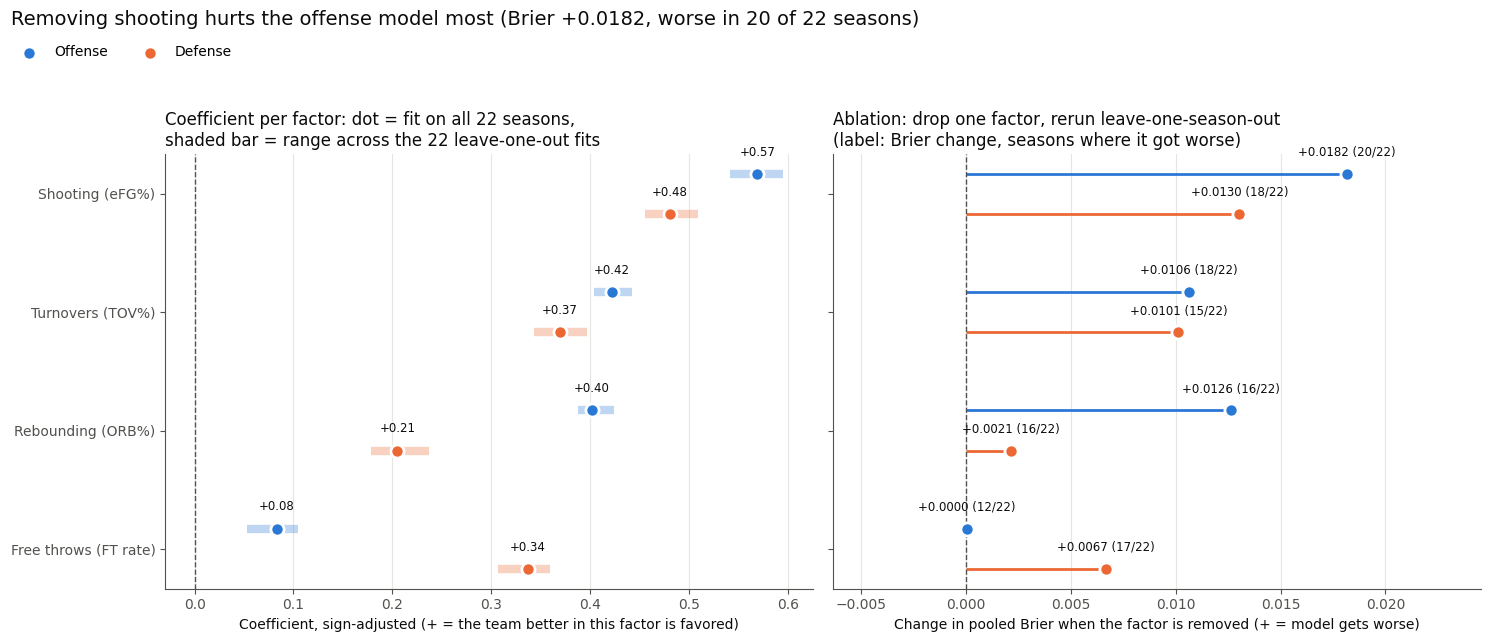

COEFFICIENTS (strength = sign-adjusted; odds_x_per_1sd = odds multiplier for a 1-SD edge)
   side                factor  raw_coef  strength  odds_x_per_1sd  fold_min  fold_max  folds_expected_sign
Offense       Shooting (eFG%)     0.569     0.569           1.767     0.542     0.596                   22
Offense      Turnovers (TOV%)    -0.422     0.422           1.525     0.404     0.442                   22
Offense     Rebounding (ORB%)     0.402     0.402           1.495     0.387     0.424                   22
Offense Free throws (FT rate)     0.083     0.083           1.087     0.053     0.105                   22
Defense       Shooting (eFG%)    -0.480     0.480           1.617     0.456     0.509                   22
Defense      Turnovers (TOV%)     0.369     0.369           1.446     0.343     0.397                   22
Defense     Rebounding (ORB%)    -0.205     0.205           1.228     0.179     0.237                   22
Defense Free throws (FT rate)    -0.337     0.337     

In [16]:
#@title Coefficients: which factors carry the weight, and how stable are they?
# Needs `matchups`, OFF_FEATURES, DEF_FEATURES from the feature cell.
# Three views:
#   1. Coefficients from one fit on all 22 seasons (what the final model uses)
#   2. The same coefficient in each of the 22 leave-one-season-out fits (is it stable?)
#   3. Ablation: drop one factor, rerun leave-one-season-out, see how much Brier gets worse
#      (the cleanest answer to "offense wins because of X")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
FACTOR_NAMES = {"eFG": "Shooting (eFG%)", "TOV": "Turnovers (TOV%)",
                "ORB": "Rebounding (ORB%)", "FTR": "Free throws (FT rate)"}
# +1 if a HIGHER value is better for the team, -1 if LOWER is better (same as the feature-visual cell)
BETTER_IF_HIGHER = {"Off_eFG": 1, "Off_TOV": -1, "Off_ORB": 1, "Off_FTR": 1,
                    "Def_eFG": -1, "Def_TOV": 1, "Def_ORB": -1, "Def_FTR": -1}
SIDES = {"Offense": OFF_FEATURES, "Defense": DEF_FEATURES}
SIDE_COLORS = {"Offense": BLUE, "Defense": ORANGE}
SEASON_LIST = sorted(matchups.Season.unique())

def fit(X, y):
    return LogisticRegression(max_iter=1000).fit(X, y)

def loso_sq_errors(feats):
    """Leave-one-season-out squared error for every game, using only `feats`."""
    se = pd.Series(np.nan, index=matchups.index)
    for s in SEASON_LIST:
        tr, te = matchups.Season != s, matchups.Season == s
        p = fit(matchups.loc[tr, feats], matchups.loc[tr, "Label"]).predict_proba(matchups.loc[te, feats])[:, 1]
        se[te] = (p - matchups.loc[te, "Label"]) ** 2
    return se

def direction(feat):          # "Off_eFG_diff" -> +1 / -1
    return BETTER_IF_HIGHER[feat.replace("_diff", "")]

def factor(feat):             # "Off_eFG_diff" -> "eFG"
    return feat.split("_")[1]

# ---- 1 + 2. Full-data coefficients and per-fold coefficients ----
# Features are season z-score differences, so coefficients are on the same scale and comparable.
# Multiplying by the direction makes "positive = the better team in this factor is favored".
coef_rows, fold_rows = [], []
for side, feats in SIDES.items():
    full = fit(matchups[feats], matchups.Label)
    for f, b in zip(feats, full.coef_[0]):
        coef_rows.append({"side": side, "factor": factor(f), "raw_coef": b,
                          "strength": b * direction(f), "odds_x_per_1sd": np.exp(abs(b))})
    for s in SEASON_LIST:
        tr = matchups.Season != s
        m = fit(matchups.loc[tr, feats], matchups.loc[tr, "Label"])
        for f, b in zip(feats, m.coef_[0]):
            fold_rows.append({"side": side, "factor": factor(f), "held_out": s, "strength": b * direction(f)})
coefs = pd.DataFrame(coef_rows)
folds = pd.DataFrame(fold_rows)
fold_summary = (folds.groupby(["side", "factor"]).strength
                .agg(fold_min="min", fold_max="max",
                     folds_expected_sign=lambda x: int((x > 0).sum())).reset_index())
coefs = coefs.merge(fold_summary, on=["side", "factor"])

# ---- 3. Ablation: drop one factor at a time ----
abl_rows = []
for side, feats in SIDES.items():
    base_se = loso_sq_errors(feats)
    base_by_season = base_se.groupby(matchups.Season).mean()
    for f in feats:
        se = loso_sq_errors([x for x in feats if x != f])
        drop_by_season = se.groupby(matchups.Season).mean()
        abl_rows.append({"side": side, "factor": factor(f),
                         "brier_increase": se.mean() - base_se.mean(),
                         "seasons_hurt": int((drop_by_season > base_by_season).sum())})
ablation = pd.DataFrame(abl_rows)

# ---- Figure ----
order = list(FACTOR_NAMES)
y = np.arange(len(order))[::-1]
offset = {"Offense": 0.17, "Defense": -0.17}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
top_off = ablation[ablation.side == "Offense"].sort_values("brier_increase").iloc[-1]
fig.suptitle(f"Removing {FACTOR_NAMES[top_off.factor].split(' (')[0].lower()} hurts the offense model most "
             f"(Brier +{top_off.brier_increase:.4f}, worse in {top_off.seasons_hurt} of {len(SEASON_LIST)} seasons)",
             fontsize=14, x=0.01, ha="left", color=INK)

# Left: coefficient strength, full-data dot + range across the 22 folds
for side in SIDES:
    d = coefs[coefs.side == side].set_index("factor").loc[order]
    yy = y + offset[side]
    ax1.hlines(yy, d.fold_min, d.fold_max, color=SIDE_COLORS[side], linewidth=6, alpha=0.3)
    ax1.scatter(d.strength, yy, s=90, color=SIDE_COLORS[side], edgecolor="white", linewidth=2,
                zorder=3, label=side)
    for yv, v in zip(yy, d.strength):
        ax1.text(v, yv + 0.13, f"{v:+.2f}", ha="center", va="bottom", fontsize=8.5, color=INK)
ax1.axvline(0, color=MUTED, linewidth=1, linestyle="--")
ax1.set_yticks(y, [FACTOR_NAMES[f] for f in order])
ax1.set_xlabel("Coefficient, sign-adjusted (+ = the team better in this factor is favored)")
ax1.set_title("Coefficient per factor: dot = fit on all 22 seasons,\nshaded bar = range across the 22 leave-one-out fits",
              loc="left", color=INK)
ax1.grid(axis="y", visible=False)

# Right: ablation
for side in SIDES:
    d = ablation[ablation.side == side].set_index("factor").loc[order]
    yy = y + offset[side]
    ax2.hlines(yy, 0, d.brier_increase, color=SIDE_COLORS[side], linewidth=2)
    ax2.scatter(d.brier_increase, yy, s=90, color=SIDE_COLORS[side], edgecolor="white", linewidth=2, zorder=3)
    for yv, v, n in zip(yy, d.brier_increase, d.seasons_hurt):
        ax2.text(v, yv + 0.13, f"{v:+.4f} ({n}/{len(SEASON_LIST)})", ha="center", va="bottom",
                 fontsize=8.5, color=INK)
ax2.axvline(0, color=MUTED, linewidth=1, linestyle="--")
ax2.set_xlabel("Change in pooled Brier when the factor is removed (+ = model gets worse)")
ax2.set_title("Ablation: drop one factor, rerun leave-one-season-out\n(label: Brier change, seasons where it got worse)",
              loc="left", color=INK)
ax2.grid(axis="y", visible=False)
pad = max(ablation.brier_increase.abs().max() * 0.35, 0.001)
ax2.set_xlim(min(ablation.brier_increase.min(), 0) - pad, ablation.brier_increase.max() + pad)

fig.legend(*ax1.get_legend_handles_labels(), frameon=False, loc="upper left",
           bbox_to_anchor=(0.005, 0.945), ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.savefig("coefficients_ablation.png", dpi=200, bbox_inches="tight")
plt.show()

# ---- Tables ----
show = coefs.assign(factor=coefs.factor.map(FACTOR_NAMES))
print("COEFFICIENTS (strength = sign-adjusted; odds_x_per_1sd = odds multiplier for a 1-SD edge)")
print(show[["side", "factor", "raw_coef", "strength", "odds_x_per_1sd", "fold_min", "fold_max",
            "folds_expected_sign"]].round(3).to_string(index=False))
print("\nABLATION (Brier change when the factor is dropped; seasons_hurt out of", len(SEASON_LIST), ")")
print(ablation.assign(factor=ablation.factor.map(FACTOR_NAMES)).round(4).to_string(index=False))
flipped = coefs[coefs.strength < 0]
if len(flipped):
    print("\nNote: these factors point the 'wrong' way (the better team is disfavored):")
    for r in flipped.itertuples():
        print(f"  {r.side} {FACTOR_NAMES[r.factor]}: strength {r.strength:+.3f}, "
              f"expected sign in {r.folds_expected_sign}/{len(SEASON_LIST)} folds")


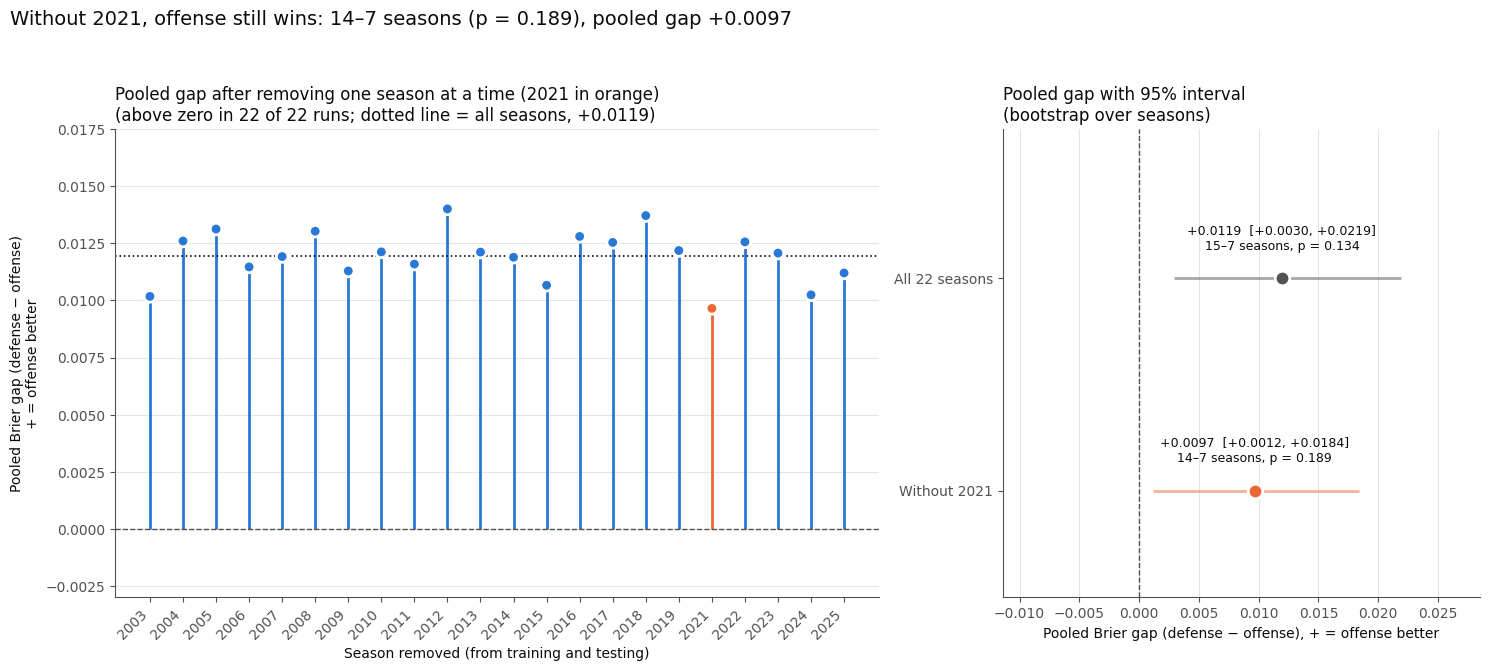

ALL SEASONS vs WITHOUT 2021
run             All 22 seasons  Without 2021
seasons                     22            21
games                     1385          1323
offense_better              15            14
defense_better               7             7
sign_test_p             0.1338        0.1892
pooled_gap              0.0119        0.0097
gap_lo                   0.003        0.0012
gap_hi                  0.0219        0.0184
brier_seed              0.1905        0.1888
brier_off               0.2037        0.2037
brier_def               0.2156        0.2133

DROP ONE SEASON AT A TIME
 dropped  pooled_gap  offense_better  of
    2003      0.0102              13  21
    2004      0.0126              15  21
    2005      0.0131              15  21
    2006      0.0115              15  21
    2007      0.0119              14  21
    2008      0.0130              16  21
    2009      0.0113              13  21
    2010      0.0121              14  21
    2011      0.0116              14

In [17]:
#@title Robustness: does the verdict hold without 2021 (or without any single season)?
# Needs `matchups`, SEED_FEATURES, OFF_FEATURES, DEF_FEATURES from the feature cell.
# 2021 is removed from BOTH training and testing (not just deleted from the results table),
# because in the main run it was in the training data for the other 21 folds.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
RNG = np.random.default_rng(2021)
N_BOOT = 2000
MODELS = {"seed": SEED_FEATURES, "off": OFF_FEATURES, "def": DEF_FEATURES}
MODEL_NAMES = {"seed": "Seed-only", "off": "Offense-only", "def": "Defense-only"}

def run_loso(data):
    """Leave-one-season-out on `data`; returns per-game squared errors for each model."""
    out = data[["Season", "Label"]].copy()
    for key, feats in MODELS.items():
        se = pd.Series(np.nan, index=data.index)
        for s in sorted(data.Season.unique()):
            tr, te = data.Season != s, data.Season == s
            clf = LogisticRegression(max_iter=1000).fit(data.loc[tr, feats], data.loc[tr, "Label"])
            se[te] = (clf.predict_proba(data.loc[te, feats])[:, 1] - data.loc[te, "Label"]) ** 2
        out["se_" + key] = se
    out["gap"] = out.se_def - out.se_off            # > 0 means offense forecast better
    return out

def summarize(res, label):
    by_season = res.groupby("Season").gap.mean()
    off_w, def_w = int((by_season > 0).sum()), int((by_season < 0).sum())
    # pooled gap interval: resample whole seasons
    seasons = by_season.index.to_numpy()
    sums = res.groupby("Season").gap.sum().loc[seasons].to_numpy()
    ns = res.groupby("Season").size().loc[seasons].to_numpy()
    idx = RNG.integers(0, len(seasons), size=(N_BOOT, len(seasons)))
    boot = sums[idx].sum(axis=1) / ns[idx].sum(axis=1)
    return {"run": label, "seasons": len(seasons), "games": len(res),
            "offense_better": off_w, "defense_better": def_w,
            "sign_test_p": binomtest(off_w, off_w + def_w, 0.5).pvalue,
            "pooled_gap": res.gap.mean(),
            "gap_lo": np.percentile(boot, 2.5), "gap_hi": np.percentile(boot, 97.5),
            **{f"brier_{k}": res["se_" + k].mean() for k in MODELS}}

# ---- 1. Main comparison: all seasons vs. without 2021 ----
res_all = run_loso(matchups)
res_no21 = run_loso(matchups[matchups.Season != 2021].reset_index(drop=True))
compare = pd.DataFrame([summarize(res_all, "All 22 seasons"), summarize(res_no21, "Without 2021")])

# ---- 2. Drop every season in turn (is 2021 special, or is any single season driving it?) ----
jack = []
for s in sorted(matchups.Season.unique()):
    r = run_loso(matchups[matchups.Season != s].reset_index(drop=True))
    gaps = r.groupby("Season").gap.mean()
    jack.append({"dropped": s, "pooled_gap": r.gap.mean(),
                 "offense_better": int((gaps > 0).sum()), "of": len(gaps)})
jack = pd.DataFrame(jack)

# ---- Figure ----
full = compare.iloc[0]
no21 = compare.iloc[1]
holds = (no21.gap_lo > 0) or (no21.gap_hi < 0)
verdict = "offense" if no21.pooled_gap > 0 else "defense"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"width_ratios": [1.6, 1]})
fig.suptitle((f"Without 2021, {verdict} still wins: {int(no21.offense_better)}–{int(no21.defense_better)} "
              f"seasons (p = {no21.sign_test_p:.3f}), pooled gap {no21.pooled_gap:+.4f}")
             if holds else
             f"Without 2021 the pooled gap's interval crosses zero ({no21.gap_lo:+.4f} to {no21.gap_hi:+.4f})",
             fontsize=14, x=0.01, ha="left", color=INK)

# Left: pooled gap after dropping each season
x = np.arange(len(jack))
colors = [ORANGE if s == 2021 else BLUE for s in jack.dropped]
ax1.vlines(x, 0, jack.pooled_gap, color=colors, linewidth=2)
ax1.scatter(x, jack.pooled_gap, s=70, color=colors, edgecolor="white", linewidth=2, zorder=3)
ax1.axhline(full.pooled_gap, color=INK, linewidth=1.2, linestyle=":")
ax1.axhline(0, color=MUTED, linewidth=1, linestyle="--")
ax1.set_xticks(x, [str(s) for s in jack.dropped], rotation=45, ha="right")
ax1.set_xlabel("Season removed (from training and testing)")
ax1.set_ylabel("Pooled Brier gap (defense − offense)\n+ = offense better")
ax1.set_title("Pooled gap after removing one season at a time (2021 in orange)\n"
              f"(above zero in {int((jack.pooled_gap > 0).sum())} of {len(jack)} runs; dotted line = all seasons, {full.pooled_gap:+.4f})",
              loc="left", color=INK)
ax1.set_ylim(min(0, jack.pooled_gap.min()) - abs(full.pooled_gap) * 0.25, jack.pooled_gap.max() * 1.25)
ax1.grid(axis="x", visible=False)

# Right: pooled gap with its 95% interval (resampling whole seasons), with vs without 2021
y = np.array([1, 0])
for yy, (_, r), c in zip(y, compare.iterrows(), (MUTED, ORANGE)):
    ax2.hlines(yy, r.gap_lo, r.gap_hi, color=c, linewidth=2, alpha=0.5)
    ax2.scatter(r.pooled_gap, yy, s=110, color=c, edgecolor="white", linewidth=2, zorder=3)
    ax2.text(r.pooled_gap, yy + 0.12,
             f"{r.pooled_gap:+.4f}  [{r.gap_lo:+.4f}, {r.gap_hi:+.4f}]\n"
             f"{int(r.offense_better)}–{int(r.defense_better)} seasons, p = {r.sign_test_p:.3f}",
             ha="center", va="bottom", fontsize=9, color=INK)
ax2.axvline(0, color=MUTED, linewidth=1, linestyle="--")
ax2.set_yticks(y, compare.run)
span = max(abs(compare.gap_lo.min()), abs(compare.gap_hi.max())) * 1.3
ax2.set_xlim(-span * 0.4, span)
ax2.set_ylim(-0.5, 1.7)
ax2.set_xlabel("Pooled Brier gap (defense − offense), + = offense better")
ax2.set_title("Pooled gap with 95% interval\n(bootstrap over seasons)", loc="left", color=INK)
ax2.grid(axis="y", visible=False)

fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("robustness_no_2021.png", dpi=200, bbox_inches="tight")
plt.show()

# ---- Tables ----
print("ALL SEASONS vs WITHOUT 2021")
print(compare.round(4).T.to_string(header=False))
print("\nDROP ONE SEASON AT A TIME")
print(jack.round(4).to_string(index=False))


## Beyond seeding: seed + offense vs. seed + defense

Neither side beats seeding on its own, so this section asks a different question: **once the committee's seed is known, which side's stats add more?**

| Model | Inputs (Team A − Team B) | Count |
|---|---|---|
| **Seed-only** | seed difference | 1 |
| **Seed + offense** | seed difference + 4 offensive factors | 5 |
| **Seed + defense** | seed difference + 4 defensive factors | 5 |

Both models get the same seed feature, so any difference in what they add comes from offense vs. defense. The method is the same as before (logistic regression, leave-one-season-out, Brier score).

**Gain** = seed-only Brier − (seed + side) Brier. A positive gain means adding that side improved the forecast. The same rule as the main comparison decides what counts as real: the season-bootstrap 95% interval must exclude zero, **and** the same direction must hold in most of the 22 seasons.

*Expect small gains. The committee already looks at efficiency when it seeds teams, so seeds overlap with the Four Factors. Because seed and the factors are correlated, the factor coefficients in these models shrink, so read factor strength from the side-only models above, not from these.*

BRIER BY HELD-OUT SEASON, WITH SEED IN EVERY MODEL (lower Brier is better; gain > 0 = side helped)
        Games    Seed  Seed + off  Seed + def  Off gain  Def gain  Gap (Off - Def)
Season                                                                            
2003       63  0.1762      0.1746      0.1863    0.0016   -0.0101           0.0116
2004       63  0.1716      0.1778      0.1718   -0.0062   -0.0003          -0.0060
2005       63  0.1852      0.1863      0.1759   -0.0011    0.0093          -0.0104
2006       63  0.2043      0.1998      0.2003    0.0046    0.0040           0.0006
2007       63  0.1419      0.1433      0.1427   -0.0014   -0.0008          -0.0006
2008       63  0.1771      0.1720      0.1718    0.0052    0.0054          -0.0002
2009       63  0.1665      0.1661      0.1712    0.0005   -0.0046           0.0051
2010       63  0.2011      0.1972      0.1990    0.0039    0.0021           0.0018
2011       63  0.2111      0.2126      0.2189   -0.0015   -0.0078      

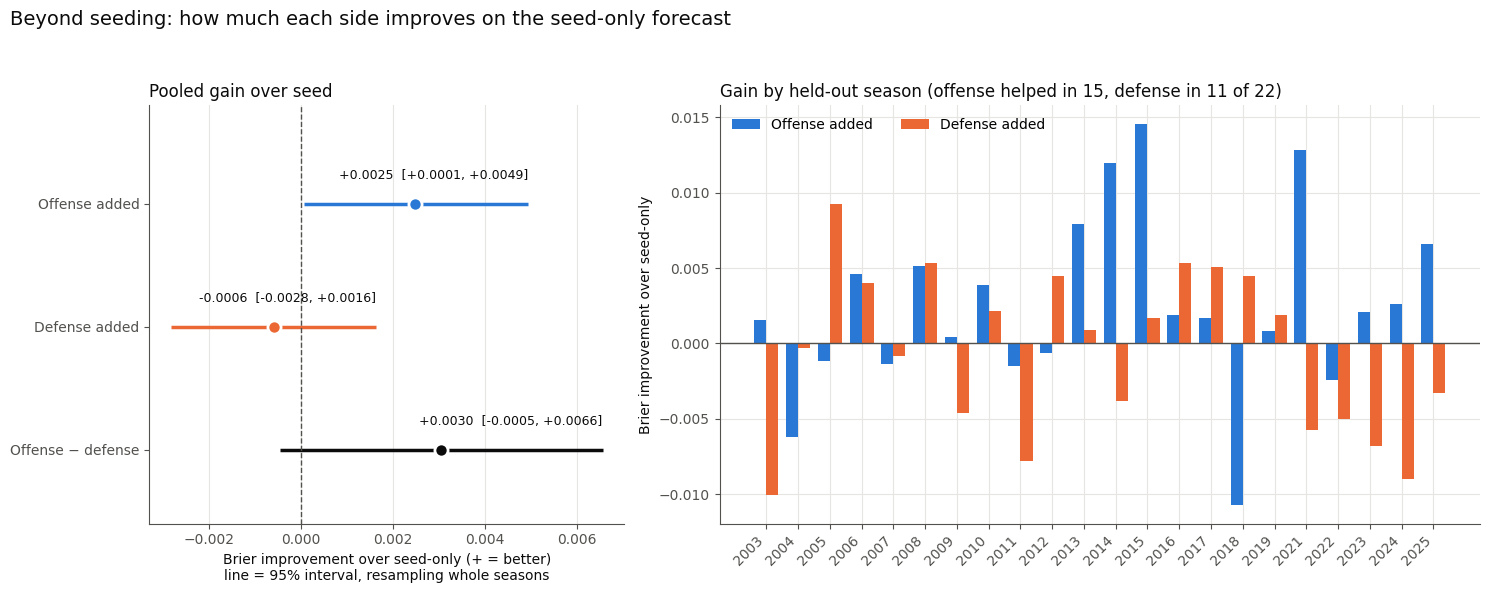

In [18]:
#@title Beyond seeding: what do offense and defense add on top of seed?
# Needs `matchups`, SEED_FEATURES, OFF_FEATURES, DEF_FEATURES from the feature cell.
# Self-contained: re-runs leave-one-season-out for three models and uses its own
# variable names (prefix bs_), so it doesn't overwrite anything the conclusion cell reads.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
BS_N_BOOT, BS_RANDOM_SEED = 10_000, 2010

BS_MODELS = {
    "seed":     SEED_FEATURES,                  # same baseline as before
    "seed_off": SEED_FEATURES + OFF_FEATURES,   # seed + 4 offense factors
    "seed_def": SEED_FEATURES + DEF_FEATURES,   # seed + 4 defense factors
}
BS_NAMES = {"seed": "Seed-only", "seed_off": "Seed + offense", "seed_def": "Seed + defense"}

# ---------- 1. Leave-one-season-out predictions (same method as the main models) ----------
bs = matchups[["Season", "Label"]].copy()
for season in sorted(matchups.Season.unique()):
    test = matchups.Season == season
    for key, cols in BS_MODELS.items():
        model = make_pipeline(StandardScaler(), LogisticRegression())
        model.fit(matchups.loc[~test, cols], matchups.loc[~test, "Label"])
        bs.loc[test, "p_" + key] = model.predict_proba(matchups.loc[test, cols])[:, 1]

assert bs.filter(like="p_").notna().all().all(), "some games were never predicted"
for key in BS_MODELS:
    bs["se_" + key] = (bs["p_" + key] - bs.Label) ** 2   # per-game Brier

# Gain = how much Brier drops when a side is added to seed (positive = the side helps)
bs["gain_off"] = bs.se_seed - bs.se_seed_off
bs["gain_def"] = bs.se_seed - bs.se_seed_def
bs["gain_gap"] = bs.gain_off - bs.gain_def      # same sign as before: + = offense adds more

# ---------- 2. Per-season gains ----------
bs_season = bs.groupby("Season")[["se_seed", "se_seed_off", "se_seed_def",
                                  "gain_off", "gain_def", "gain_gap"]].mean()
bs_season.columns = ["Seed", "Seed + off", "Seed + def", "Off gain", "Def gain", "Gap (Off - Def)"]
bs_season.insert(0, "Games", bs.groupby("Season").size())
print("BRIER BY HELD-OUT SEASON, WITH SEED IN EVERY MODEL (lower Brier is better; gain > 0 = side helped)")
print(bs_season.round(4).to_string())

# ---------- 3. Season-level bootstrap (whole seasons resampled, same picks for every quantity) ----------
seasons = bs_season.index.to_numpy()
sums = bs.groupby("Season")[["gain_off", "gain_def", "gain_gap"]].sum().loc[seasons]
sizes = bs.groupby("Season").size().loc[seasons].to_numpy()
rng = np.random.default_rng(BS_RANDOM_SEED)
picks = rng.integers(0, len(seasons), size=(BS_N_BOOT, len(seasons)))
boot_n = sizes[picks].sum(axis=1)

rows = []
for col, label in [("gain_off", "Offense gain over seed"),
                   ("gain_def", "Defense gain over seed"),
                   ("gain_gap", "Offense gain - defense gain")]:
    boot = sums[col].to_numpy()[picks].sum(axis=1) / boot_n
    lo, hi = np.percentile(boot, [2.5, 97.5])
    by_s = bs.groupby("Season")[col].mean()
    rows.append({"quantity": label, "pooled": bs[col].mean(), "lo": lo, "hi": hi,
                 "excludes_zero": lo > 0 or hi < 0,
                 "seasons_positive": int((by_s > 0).sum()), "seasons_negative": int((by_s < 0).sum())})
beyond_seed = pd.DataFrame(rows).set_index("quantity")

bs_pooled = pd.DataFrame({BS_NAMES[k]: {"Brier": bs["se_" + k].mean(),
                                         "Accuracy": ((bs["p_" + k] > 0.5) == (bs.Label == 1)).mean()}
                          for k in BS_MODELS}).T
print(f"\nPOOLED ACROSS {len(seasons)} SEASONS ({len(bs):,} games)")
print(bs_pooled.round(4).to_string())
print("\nGAIN OVER SEED-ONLY (Brier drop; + = adding the side helped)")
print(beyond_seed.round(4).to_string())

# ---------- 4. Verdict (same two-condition rule as the main comparison) ----------
def gain_verdict(label, side):
    r = beyond_seed.loc[label]
    helps = r.excludes_zero and r.pooled > 0 and r.seasons_positive > len(seasons) / 2
    return (f"{side} adds real information beyond seed" if helps else
            f"{side} does not clearly add information beyond seed")

g = beyond_seed.loc["Offense gain - defense gain"]
leader = "Offense" if g.pooled > 0 else "Defense"
leader_seasons = g.seasons_positive if leader == "Offense" else g.seasons_negative
gap_real = g.excludes_zero and leader_seasons > len(seasons) / 2

print("\nVERDICT")
print("  " + gain_verdict("Offense gain over seed", "Offense"))
print("  " + gain_verdict("Defense gain over seed", "Defense"))
print(f"  {leader} adds more beyond seed in {leader_seasons} of {len(seasons)} seasons; "
      f"interval for the difference [{g.lo:+.4f}, {g.hi:+.4f}] "
      + ("excludes zero -> the difference is real." if gap_real else
         "-> treat the difference as a tie."))

# ---------- 5. Figure ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.6]})
fig.suptitle("Beyond seeding: how much each side improves on the seed-only forecast",
             fontsize=14, x=0.01, ha="left", color=INK)

# Left: pooled gain with 95% season-bootstrap interval
items = [("Offense gain over seed", "Offense added", BLUE),
         ("Defense gain over seed", "Defense added", ORANGE),
         ("Offense gain - defense gain", "Offense − defense", INK)]
y = np.arange(len(items))[::-1]
for yy, (key, label, color) in zip(y, items):
    r = beyond_seed.loc[key]
    ax1.hlines(yy, r.lo, r.hi, color=color, linewidth=2.5)
    ax1.scatter(r.pooled, yy, s=90, color=color, edgecolor="white", linewidth=2, zorder=3)
    ax1.text(r.hi, yy + 0.18, f"{r.pooled:+.4f}  [{r.lo:+.4f}, {r.hi:+.4f}]",
             fontsize=9, color=INK, ha="right", va="bottom")
ax1.axvline(0, color=MUTED, linewidth=1, linestyle="--")
ax1.set_yticks(y, [label for _, label, _ in items])
ax1.set_ylim(-0.6, len(items) - 0.2)
ax1.set_xlabel("Brier improvement over seed-only (+ = better)\nline = 95% interval, resampling whole seasons")
ax1.set_title("Pooled gain over seed", loc="left", color=INK)
ax1.grid(axis="y", visible=False)

# Right: gain by season
x = np.arange(len(seasons))
w = 0.38
ax2.bar(x - w / 2, bs_season["Off gain"], width=w, color=BLUE, label="Offense added")
ax2.bar(x + w / 2, bs_season["Def gain"], width=w, color=ORANGE, label="Defense added")
ax2.axhline(0, color=MUTED, linewidth=1)
ax2.set_xticks(x, [str(s) for s in seasons], rotation=45, ha="right")
ax2.set_ylabel("Brier improvement over seed-only")
ax2.set_title(f"Gain by held-out season (offense helped in {int(beyond_seed.loc['Offense gain over seed'].seasons_positive)}, "
              f"defense in {int(beyond_seed.loc['Defense gain over seed'].seasons_positive)} of {len(seasons)})",
              loc="left", color=INK)
ax2.legend(frameon=False, loc="upper left", ncol=2)
for ax in (ax1, ax2):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

In [19]:
#@title Conclusion (written from the results above, so the numbers always match)
# Needs the variables from the results, coefficients and robustness cells:
#   by_season, off_wins, def_wins, sign_p, pooled, pooled_gap, pooled_gap_lo, pooled_gap_hi,
#   ablation, coefs, compare, jack
from IPython.display import Markdown, display

winner, loser = ("offense", "defense") if pooled_gap > 0 else ("defense", "offense")
w_side, l_side = winner.capitalize(), loser.capitalize()
w_key, l_key = ("off", "def") if winner == "offense" else ("def", "off")
clear = pooled_gap_lo > 0 or pooled_gap_hi < 0
n_seasons = off_wins + def_wins
w_seasons = off_wins if winner == "offense" else def_wins
l_seasons = n_seasons - w_seasons

# Seed baseline
seed_b, w_b, l_b = pooled.loc["seed", "brier"], pooled.loc[w_key, "brier"], pooled.loc[l_key, "brier"]
beats_seed = w_b < seed_b

# Which factors carry the winning side (ablation, biggest Brier increase first)
abl_w = ablation[ablation.side == w_side].sort_values("brier_increase", ascending=False)
top, second = abl_w.iloc[0], abl_w.iloc[1]
useless = abl_w[abl_w.brier_increase <= 0].factor.map(FACTOR_NAMES).str.split(" \\(").str[0].str.lower().tolist()
top_coef = coefs[(coefs.side == w_side) & (coefs.factor == top.factor)].iloc[0]
abl_l = ablation[ablation.side == l_side].sort_values("brier_increase", ascending=False).iloc[0]
name = lambda f: FACTOR_NAMES[f].split(" (")[0].lower()

# Robustness
no21 = compare.set_index("run").loc["Without 2021"]
no21_w = int(no21.offense_better if winner == "offense" else no21.defense_better)
no21_l = int(no21.defense_better if winner == "offense" else no21.offense_better)
no21_holds = (no21.gap_lo > 0) if winner == "offense" else (no21.gap_hi < 0)
jack_same = int(((jack.pooled_gap > 0) if winner == "offense" else (jack.pooled_gap < 0)).sum())
season_21 = by_season.set_index("Season").gap.get(2021, np.nan)
rank_21 = int((by_season.gap.abs() > abs(season_21)).sum()) + 1
rank_txt = "the largest single-season gap" if rank_21 == 1 else f"the #{rank_21} largest of {n_seasons} season gaps"
jack_txt = ("so no single season drives the verdict." if jack_same == len(jack) else
            f"so the verdict depends on {len(jack) - jack_same} specific season(s): "
            f"{', '.join(str(s) for s in jack.loc[(jack.pooled_gap <= 0) if winner == 'offense' else (jack.pooled_gap >= 0), 'dropped'])}.")

if beats_seed:
    seed_line = (f"- **{w_side} stats beat seeding:** the seed-only model scored {seed_b:.4f}, worse than "
                 f"{w_side.lower()} ({w_b:.4f}). Four regular-season rates alone out-forecast the committee's seeds.")
else:
    seed_line = (f"- **Neither side beat seeding:** the seed-only model scored {seed_b:.4f}, better than both. "
                 "That's expected, because seeds pack in much more than four box-score rates (schedule strength, "
                 "efficiency ratings, the committee's judgment). The question here is which side carries more "
                 "signal, not whether either one replaces seeding.")

md = f"""
## Conclusion

**Question:** Do a team's offensive or defensive Four Factors better forecast who wins a men's NCAA tournament game?

**Answer: {winner}{"" if clear else ", but not decisively"}.** With leave-one-season-out testing on {len(oos):,} tournament games from 2003–2025 (no 2020), the offense-only model and the defense-only model were compared one season at a time:

- **{w_side} forecast better in {w_seasons} of {n_seasons} seasons** (sign test p = {sign_p:.3f}).
- **Pooled Brier: {w_side.lower()} {w_b:.4f} vs. {l_side.lower()} {l_b:.4f}.** The gap is {abs(pooled_gap):.4f}, with a 95% interval of [{pooled_gap_lo:+.4f}, {pooled_gap_hi:+.4f}] from resampling whole seasons{", which excludes zero" if clear else ", which includes zero"}.
{seed_line}

**Why {winner}?** In the {w_side.lower()} model, **{name(top.factor)}** carries the most weight: removing it made pooled Brier worse by {top.brier_increase:.4f} and hurt the forecast in {top.seasons_hurt} of {n_seasons} seasons. Its coefficient means a 1-SD edge multiplies a team's odds of winning by about {top_coef.odds_x_per_1sd:.2f}. **{name(second.factor).capitalize()}** is second (+{max(second.brier_increase, 0):.4f}).{f" Removing {" or ".join(useless)} on its own did not make the model worse, so those factors add little beyond the others." if useless else ""} On the {l_side.lower()} side, {name(abl_l.factor)} matters most (+{max(abl_l.brier_increase, 0):.4f}).

**Robustness.** 2021 (COVID-shortened season) was {rank_txt} ({season_21:+.3f}). With 2021 removed from both training and testing, {winner} still wins **{no21_w}–{no21_l}** (p = {no21.sign_test_p:.3f}), with a pooled gap of {abs(no21.pooled_gap):.4f} [{no21.gap_lo:+.4f}, {no21.gap_hi:+.4f}]{"" if no21_holds else ". The interval now includes zero, so the result is weaker without 2021"}. Removing any one of the {len(jack)} seasons leaves {winner} ahead in **{jack_same} of {len(jack)}** runs, {jack_txt}

**Bottom line for bracket makers:** {f"when two teams' profiles disagree, the one with the better {winner} — especially better {name(top.factor)} — has been the safer pick. But a seed line still holds more information than either side's Four Factors alone." if not beats_seed else f"the team with the better {winner}, especially better {name(top.factor)}, has been the safer pick, even compared with seeds."}
"""
display(Markdown(md))



## Conclusion

**Question:** Do a team's offensive or defensive Four Factors better forecast who wins a men's NCAA tournament game?

**Answer: offense.** With leave-one-season-out testing on 1,385 tournament games from 2003–2025 (no 2020), the offense-only model and the defense-only model were compared one season at a time:

- **Offense forecast better in 15 of 22 seasons** (sign test p = 0.134).
- **Pooled Brier: offense 0.2037 vs. defense 0.2156.** The gap is 0.0119, with a 95% interval of [+0.0025, +0.0217] from resampling whole seasons, which excludes zero.
- **Neither side beat seeding:** the seed-only model scored 0.1905, better than both. That's expected, because seeds pack in much more than four box-score rates (schedule strength, efficiency ratings, the committee's judgment). The question here is which side carries more signal, not whether either one replaces seeding.

**Why offense?** In the offense model, **shooting** carries the most weight: removing it made pooled Brier worse by 0.0182 and hurt the forecast in 20 of 22 seasons. Its coefficient means a 1-SD edge multiplies a team's odds of winning by about 1.77. **Rebounding** is second (+0.0126). On the defense side, shooting matters most (+0.0130).

**Robustness.** 2021 (COVID-shortened season) was the largest single-season gap (+0.061). With 2021 removed from both training and testing, offense still wins **14–7** (p = 0.189), with a pooled gap of 0.0097 [+0.0012, +0.0184]. Removing any one of the 22 seasons leaves offense ahead in **22 of 22** runs, so no single season drives the verdict.

**Bottom line for bracket makers:** when two teams' profiles disagree, the one with the better offense — especially better shooting — has been the safer pick. But a seed line still holds more information than either side's Four Factors alone.


## Limitations

**What the claim covers.** This project asks which side's stats *forecast* tournament games better, not which side *matters more* for winning basketball games. A better forecast means a side's season-long numbers are a more reliable signal of tournament strength. That could be because offense is more consistent from game to game, not because defense matters less on the court.

**Small samples per season.** Each tournament has only about 63 games (62 in 2021), so single-season Brier gaps are noisy: every per-season 95% interval includes zero (2021's lower bound sits right at zero). The sign test on 15 of 22 seasons is also not significant on its own (p = 0.134). The verdict rests on the pooled gap across all 22 seasons, whose season-bootstrap interval excludes zero, not on any one year.

**The opponent adjustment is simple.** Each factor is adjusted once by subtracting the average of the opponents' season rates, which removes the biggest schedule effect. But the opponents' rates are not adjusted in turn, home court is ignored, and every game counts equally. Iterative opponent-adjusted ratings like KenPom's would be cleaner, but they aren't free or in the Kaggle data. Season z-scores handle changes across eras (more threes, fewer free throws).

**Offense and defense aren't fully independent.** A team's defensive stats are its opponents' offensive stats. So "defense" here partly measures the offenses a team happened to face. This could make defensive stats noisier, and it may be part of why they forecast worse.

**Seeds already contain this information.** The selection committee looks at efficiency metrics when it seeds teams, so seeds partly include these Four Factors. The seed-only model is a reference point, not an independent competitor.

**Model choices.** Each side gets one logistic regression with sklearn's default regularization (L2, C = 1), four features, and no interactions. A more flexible model might pull more signal out of defensive stats. Keeping both sides to the same simple model makes the comparison fair, but it isn't the best possible model for either side.

**What the data doesn't capture.** The data has no injuries, roster changes, late-season form, coaching, or tournament experience, and every team's season is averaged into a single profile. Every game is treated as independent, even though the same strong teams appear in several games each year. Resampling whole seasons for the pooled interval partly accounts for that.

**Scope.** Men's Division I only, 2003–2025 (2003 is the first season with box scores; 2020 had no tournament). First Four games were dropped because both teams share a seed. The results may not carry over to the women's tournament or to regular-season games.

**Future work.**
- Replace the one-pass schedule adjustment with an iterative one (adjust opponents' ratings in turn, and account for home court).
- Fit a combined offense + defense model to see whether defense adds anything once offense is known (the seed + side models suggest it may not: defense added nothing beyond seed, offense did).
- Repeat the analysis on the women's tournament (the same Kaggle files with the `W` prefix).

# Bonus: Building a Combined Offence+Defense+Seed Model Vs. Existing Models

POOLED ACROSS 22 SEASONS (1,385 games, lower Brier is better)
                          Features   Brier  Log loss  Accuracy
Offense                          4  0.2037    0.5917    0.6809
Defense                          4  0.2156    0.6193    0.6440
Offense + defense                8  0.1921    0.5607    0.6968
Seed + offense                   5  0.1880    0.5537    0.7141
Seed + defense                   5  0.1911    0.5601    0.7047
Seed + offense + defense         9  0.1872    0.5497    0.7083

GAIN FROM ADDING ONE SIDE (Brier drop; + = the added side helped)
                                 pooled_gain      lo      hi  seasons_helped  seasons_hurt   real
question                                                                                         
Defense added to offense              0.0115  0.0047  0.0180              17             5   True
Offense added to defense              0.0235  0.0167  0.0302              21             1   True
Defense added to seed + offense       

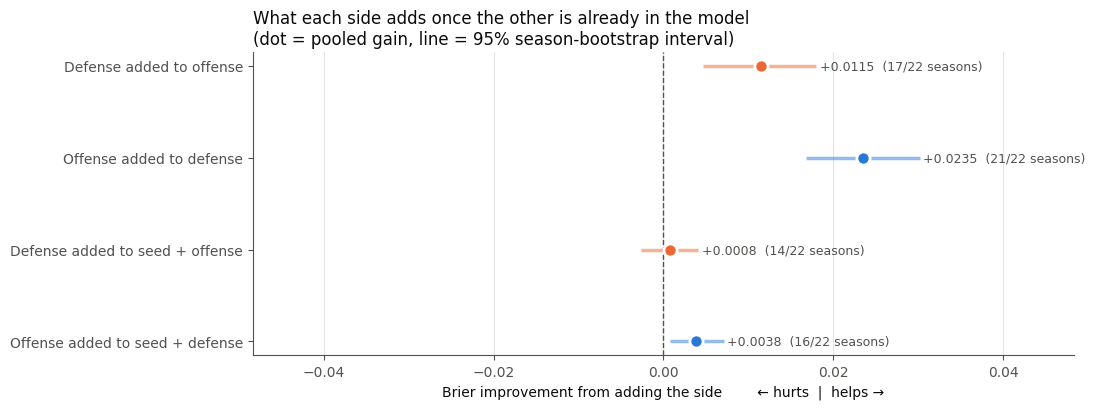

In [20]:
#@title Combined models: does defense add anything once offense is known?
# Needs `matchups`, SEED_FEATURES, OFF_FEATURES, DEF_FEATURES from the feature cell.
# Self-contained: re-runs leave-one-season-out with the same pipeline as the main
# models (StandardScaler + LogisticRegression) and uses its own variable names
# (prefix cb_), so it doesn't overwrite anything other cells read.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
CB_N_BOOT, CB_RANDOM_SEED = 10_000, 2010

CB_MODELS = {
    "off":          OFF_FEATURES,
    "def":          DEF_FEATURES,
    "off_def":      OFF_FEATURES + DEF_FEATURES,
    "seed_off":     SEED_FEATURES + OFF_FEATURES,
    "seed_def":     SEED_FEATURES + DEF_FEATURES,
    "seed_off_def": SEED_FEATURES + OFF_FEATURES + DEF_FEATURES,
}
CB_NAMES = {"off": "Offense", "def": "Defense", "off_def": "Offense + defense",
            "seed_off": "Seed + offense", "seed_def": "Seed + defense",
            "seed_off_def": "Seed + offense + defense"}

# Each question = (base model, base + one side). Gain = base Brier - bigger model Brier,
# so a positive gain means adding that side improved the forecast.
CB_QUESTIONS = {
    "Defense added to offense":        ("off", "off_def"),
    "Offense added to defense":        ("def", "off_def"),
    "Defense added to seed + offense": ("seed_off", "seed_off_def"),
    "Offense added to seed + defense": ("seed_def", "seed_off_def"),
}

# ---------- 1. Leave-one-season-out predictions ----------
cb = matchups[["Season", "Label"]].copy()
for season in sorted(matchups.Season.unique()):
    test = matchups.Season == season
    for key, cols in CB_MODELS.items():
        model = make_pipeline(StandardScaler(), LogisticRegression())
        model.fit(matchups.loc[~test, cols], matchups.loc[~test, "Label"])
        cb.loc[test, "p_" + key] = model.predict_proba(matchups.loc[test, cols])[:, 1]
assert cb.filter(like="p_").notna().all().all(), "some games were never predicted"

for key in CB_MODELS:
    cb["se_" + key] = (cb["p_" + key] - cb.Label) ** 2

# ---------- 2. Pooled scores for every model ----------
cb_overall = pd.DataFrame({
    CB_NAMES[k]: {"Features": len(CB_MODELS[k]),
                  "Brier": brier_score_loss(cb.Label, cb["p_" + k]),
                  "Log loss": log_loss(cb.Label, cb["p_" + k]),
                  "Accuracy": accuracy_score(cb.Label, cb["p_" + k] > 0.5)}
    for k in CB_MODELS}).T
cb_overall["Features"] = cb_overall["Features"].astype(int)
print(f"POOLED ACROSS {cb.Season.nunique()} SEASONS ({len(cb):,} games, lower Brier is better)")
print(cb_overall.round(4).to_string())

# ---------- 3. Gains with a season-level bootstrap + the same two-condition rule ----------
cb_seasons = np.array(sorted(cb.Season.unique()))
cb_n = cb.groupby("Season").size().loc[cb_seasons].to_numpy()
rng = np.random.default_rng(CB_RANDOM_SEED)
cb_idx = rng.integers(0, len(cb_seasons), size=(CB_N_BOOT, len(cb_seasons)))

rows, cb_season_gains = [], {}
for q, (base, big) in CB_QUESTIONS.items():
    game_gain = cb["se_" + base] - cb["se_" + big]
    sums = game_gain.groupby(cb.Season).sum().loc[cb_seasons].to_numpy()
    boot = sums[cb_idx].sum(axis=1) / cb_n[cb_idx].sum(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    by_season = game_gain.groupby(cb.Season).mean()
    cb_season_gains[q] = by_season
    pos, neg = int((by_season > 0).sum()), int((by_season < 0).sum())
    pooled_gain = game_gain.mean()
    real = (lo > 0 or hi < 0) and (max(pos, neg) > len(cb_seasons) / 2) \
           and ((pooled_gain > 0) == (pos > neg))
    rows.append({"question": q, "pooled_gain": pooled_gain, "lo": lo, "hi": hi,
                 "seasons_helped": pos, "seasons_hurt": neg, "real": real})
cb_gains = pd.DataFrame(rows).set_index("question")

print("\nGAIN FROM ADDING ONE SIDE (Brier drop; + = the added side helped)")
print(cb_gains.round(4).to_string())

print("\nVERDICT")
for q, r in cb_gains.iterrows():
    if r.real:
        word = "adds real information" if r.pooled_gain > 0 else "makes the forecast worse"
    else:
        word = "does not clearly add information (interval includes zero or seasons split)"
    print(f"  {q}: {word}  [{r.lo:+.4f}, {r.hi:+.4f}], helped in {r.seasons_helped} of {len(cb_seasons)} seasons")

# ---------- 4. Coefficients of the combined offense + defense model (all seasons) ----------
# Features are z-scored inside the pipeline, so coefficients are comparable.
# Sign-adjusted so positive = the team that is better in this factor is favored.
BETTER_IF_HIGHER = {"Off_eFG": 1, "Off_TOV": -1, "Off_ORB": 1, "Off_FTR": 1,
                    "Def_eFG": -1, "Def_TOV": 1, "Def_ORB": -1, "Def_FTR": -1}
full = make_pipeline(StandardScaler(), LogisticRegression()).fit(
    matchups[CB_MODELS["off_def"]], matchups.Label)
cb_coefs = pd.DataFrame({"feature": CB_MODELS["off_def"],
                         "raw_coef": full[-1].coef_[0]})
cb_coefs["strength"] = [b * BETTER_IF_HIGHER[f.replace("_diff", "")]
                        for f, b in zip(cb_coefs.feature, cb_coefs.raw_coef)]
cb_coefs["odds_x_per_1sd"] = np.exp(cb_coefs.strength.abs())
print("\nCOMBINED OFFENSE + DEFENSE MODEL COEFFICIENTS (strength: + = better team favored)")
print(cb_coefs.round(3).to_string(index=False))

# ---------- 5. Figure: pooled gain with 95% interval for each question ----------
fig, ax = plt.subplots(figsize=(11, 4.2))
y = np.arange(len(cb_gains))[::-1]
for yy, (q, r) in zip(y, cb_gains.iterrows()):
    color = ORANGE if q.startswith("Defense") else BLUE
    ax.hlines(yy, r.lo, r.hi, color=color, linewidth=2.5, alpha=0.5)
    ax.scatter(r.pooled_gain, yy, s=90, color=color, edgecolor="white", linewidth=2, zorder=3)
    ax.text(max(r.hi, 0) + 0.0004, yy, f"{r.pooled_gain:+.4f}  ({r.seasons_helped}/{len(cb_seasons)} seasons)",
            va="center", fontsize=9, color=MUTED)
ax.axvline(0, color=MUTED, linewidth=1, linestyle="--")
ax.set_yticks(y, list(cb_gains.index))
ax.set_xlabel("Brier improvement from adding the side        ← hurts  |  helps →")
span = max(abs(cb_gains.lo.min()), abs(cb_gains.hi.max())) * 1.6
ax.set_xlim(-span, span)
ax.grid(axis="y", visible=False)
ax.set_title("What each side adds once the other is already in the model\n"
             "(dot = pooled gain, line = 95% season-bootstrap interval)", loc="left", color=INK)
plt.tight_layout()
plt.show()

In [21]:
#@title Accuracy of each model (% of tournament games where it picked the winner)
# Needs `cb` and CB_NAMES from the combined-model cell, and `preds` from the main modeling cell (for seed-only).
import pandas as pd

acc_probs = {"Seed-only": preds["p_Seed"]}
acc_probs.update({CB_NAMES[k]: cb["p_" + k] for k in CB_NAMES})

acc_rows = []
for name, p in acc_probs.items():
    correct = (p > 0.5).astype(int) == cb.Label
    by_season = correct.groupby(cb.Season).mean()
    acc_rows.append({"Model": name, "Correct": int(correct.sum()), "Games": len(correct),
                     "Accuracy": f"{correct.mean():.1%}",
                     "Worst season": f"{by_season.min():.1%} ({by_season.idxmin()})",
                     "Best season": f"{by_season.max():.1%} ({by_season.idxmax()})"})

print("ACCURACY, LEAVE-ONE-SEASON-OUT (coin flip = 50%)")
print(pd.DataFrame(acc_rows).to_string(index=False))

ACCURACY, LEAVE-ONE-SEASON-OUT (coin flip = 50%)
                   Model  Correct  Games Accuracy Worst season  Best season
               Seed-only      982   1385    70.9% 65.1% (2014) 81.0% (2007)
                 Offense      943   1385    68.1% 61.3% (2021) 76.2% (2003)
                 Defense      892   1385    64.4% 54.8% (2021) 73.0% (2007)
       Offense + defense      965   1385    69.7% 60.3% (2011) 81.0% (2015)
          Seed + offense      989   1385    71.4% 66.7% (2011) 81.0% (2015)
          Seed + defense      976   1385    70.5% 62.9% (2021) 82.5% (2007)
Seed + offense + defense      981   1385    70.8% 62.9% (2021) 84.1% (2015)


## GenAI comparison

The models above are traditional machine learning, so this section adds a generative AI approach and puts the two side by side on the **same games, judged the same way**.

### What is compared

| Approach | How it predicts |
|---|---|
| **Logistic regression** (above) | Learned coefficients on Four Factors differences, trained on 21 seasons |
| **Paid LLM service** (Gemini) | Reads the same numbers in a prompt and reasons about them |
| **Open-source LLM** (run locally in LM Studio) | Same prompt, a model running on my own machine |

### Method

1. **Ten games**, chosen on purpose from the out-of-sample predictions: three blowout favourites, three upsets, two where the offense and defense models disagree, one near coin flip, and one from the COVID-shortened 2021 season. Each was predicted by a logistic model that never saw that game's season, so no approach has an advantage.
2. **One prompt template** for every game and every model, at temperature 0.
3. **Teams and seasons are anonymised.** All of these tournaments happened before the LLMs' training cutoffs, so naming the teams would test recall rather than reasoning. Each side appears only as "Team A" and "Team B", described by its seed and its eight schedule-adjusted Four Factors, which is the same information the logistic models receive.
4. **Two scores per reply.** An objective score (did it pick the winner, and what Brier score did its probability earn) and a manual **1–5 star** score against a rubric fixed before any reply was read, with the model names hidden while scoring.

### Why ten games is not the benchmark

Ten games is a small sample: one flipped game moves accuracy by ten points. The ten-game table shows *how* each approach behaves, with the stars capturing reasoning quality that accuracy cannot. The project's measurable benchmark stays the 1,385-game leave-one-season-out result above.

In [29]:
#@title GenAI comparison: pick ten out-of-sample games
# Needs `matchups` and `preds` from the modeling cells above.
# The ten games are chosen on purpose, not at random, so the prompt set covers the
# cases that separate a real forecaster from a lucky one: blowout favorites, upsets,
# games where offense and defense disagree, a coin flip, and the COVID season.
# Within each category the pick is a seeded shuffle, so it is reproducible but not
# hand-picked to flatter either side.
import numpy as np
import pandas as pd

GENAI_SEED = 2010
N_PROMPTS = 10

# ---- Attach the out-of-sample model probabilities (same row order as `matchups`) ----
g = matchups.copy()
for col in ("p_Seed", "p_Offense", "p_Defense"):
    g[col] = preds[col].to_numpy()
if "bs" in globals():                      # best overall model, if that cell has been run
    g["p_SeedOff"] = bs["p_seed_off"].to_numpy()

# ---- Descriptors used to build the categories ----
g["SeedGap"]  = g.SeedDiff.abs()
g["FavWon"]   = np.where(g.SeedDiff < 0, g.Label == 1,
                np.where(g.SeedDiff > 0, g.Label == 0, False))
g["Disagree"] = (g.p_Offense > 0.5) != (g.p_Defense > 0.5)

rng = np.random.default_rng(GENAI_SEED)
g["shuffle"] = rng.permutation(len(g))

BUCKETS = [
    ("Clear favorite held", lambda d: (d.SeedGap >= 8) & d.FavWon,  3),
    ("Upset",               lambda d: (d.SeedGap >= 4) & ~d.FavWon, 3),
    ("Off/def disagree",    lambda d: d.Disagree,                   2),
    ("Near coin flip",      lambda d: d.SeedGap <= 1,               1),
    ("2021 COVID season",   lambda d: d.Season == 2021,             1),
]

chosen, used = [], set()
for label, cond, k in BUCKETS:
    pool = g[cond(g)].sort_values("shuffle")
    pool = pool[~pool.index.isin(used)]
    assert len(pool) >= k, f"category '{label}' only has {len(pool)} unused games, needed {k}"
    take = pool.head(k)
    used.update(take.index)
    chosen.append(take.assign(Category=label))

games10 = pd.concat(chosen).sort_values(["Season", "DayNum"]).reset_index(drop=True)
games10.insert(0, "GameID", [f"G{i:02d}" for i in range(1, len(games10) + 1)])
assert len(games10) == N_PROMPTS and games10.GameID.is_unique

# ---- Readable summary (team names are for you, NOT for the prompts) ----
team_name = teams.set_index("TeamID").TeamName
view = pd.DataFrame({
    "GameID":   games10.GameID,
    "Season":   games10.Season,
    "Category": games10.Category,
    "Matchup":  [f"{team_name[a]} ({int(sa)}) vs {team_name[b]} ({int(sb)})"
                 for a, b, sa, sb in zip(games10.TeamA, games10.TeamB,
                                         games10.Seed_A, games10.Seed_B)],
    "Winner":   np.where(games10.Label == 1,
                         [team_name[t] for t in games10.TeamA],
                         [team_name[t] for t in games10.TeamB]),
    "p_Seed":    games10.p_Seed.round(3),
    "p_Offense": games10.p_Offense.round(3),
    "p_Defense": games10.p_Defense.round(3),
})
print("TEN PROMPT GAMES (all out-of-sample: each was predicted by a model that never saw its season)")
print(view.to_string(index=False))
print(f"\nTeam A won {games10.Label.sum()} of {len(games10)}  |  categories: "
      + ", ".join(f"{k} x{v}" for k, v in games10.Category.value_counts().items()))

TEN PROMPT GAMES (all out-of-sample: each was predicted by a model that never saw its season)
GameID  Season            Category                               Matchup       Winner  p_Seed  p_Offense  p_Defense
   G01    2003 Clear favorite held          Colorado St (14) vs Duke (3)         Duke   0.150      0.352      0.210
   G02    2003 Clear favorite held        San Diego (13) vs Stanford (4)     Stanford   0.195      0.304      0.548
   G03    2003    Off/def disagree           Kansas (2) vs Marquette (3)       Kansas   0.540      0.376      0.891
   G04    2004      Near coin flip        Georgia Tech (3) vs Kansas (4) Georgia Tech   0.538      0.492      0.568
   G05    2005 Clear favorite held        Duke (1) vs Mississippi St (9)         Duke   0.783      0.698      0.618
   G06    2010               Upset   Notre Dame (6) vs Old Dominion (11) Old Dominion   0.691      0.655      0.207
   G07    2011               Upset          Butler (8) vs Pittsburgh (1)       Butler   0.239 

In [30]:
#@title GenAI comparison: build the ten prompts (teams anonymized)
# Needs `games10` from the cell above and `team_z` from the feature cell.
#
# Two design choices make this a fair test rather than a memory test:
#   1. No team names, no season, no round. These tournaments all happened before
#      the models' training cutoffs, so naming them would test recall, not reasoning.
#   2. Signs are flipped so a positive number is ALWAYS better for that team.
#      Raw z-scores need the reader to know that low turnovers and low opponent
#      shooting are good; flipping the sign removes that trap, which would otherwise
#      measure sign-parsing instead of judgement. The logistic regression gets the
#      same information either way, because it learns a sign per feature.
import re
import pandas as pd

# +1 if a HIGHER raw value is better for the team, -1 if LOWER is better
BETTER_IF_HIGHER = {"Off_eFG": 1, "Off_TOV": -1, "Off_ORB": 1, "Off_FTR": 1,
                    "Def_eFG": -1, "Def_TOV": 1, "Def_ORB": -1, "Def_FTR": -1}
FACTOR_LABEL = {"eFG": "shooting", "TOV": "turnovers", "ORB": "rebounding", "FTR": "free throws"}
ORDER = ["eFG", "TOV", "ORB", "FTR"]

PROMPT_TEMPLATE = """Forecast the winner of one men's NCAA Division I basketball tournament game.

Each team is described by its regular-season Four Factors (shooting, turnovers,
rebounding, free throws), measured for its offense and for its defense. Every number
is in standard deviations from that season's Division I average, already adjusted for
the strength of schedule each team faced, and signed so that a POSITIVE number is
always better for that team and a NEGATIVE number is always worse. Each team's
tournament seed is also given, where 1 is the strongest and 16 the weakest. The game
is played on a neutral court.

{team_block}
Use only the information above. Reply with JSON and nothing else:
{{"winner": "A" or "B", "prob_a": <probability that Team A wins, between 0 and 1>, "reason": "<at most two sentences>"}}"""


def _ratings(season, team_id):
    """Signed-so-positive-is-better factor ratings for one team-season."""
    row = team_z[(team_z.Season == season) & (team_z.TeamID == team_id)]
    assert len(row) == 1, f"expected one row for season {season} team {team_id}, got {len(row)}"
    row = row.iloc[0]
    return {col: row[col] * sign for col, sign in BETTER_IF_HIGHER.items()}


def _team_block(side, seed, r):
    lines = [f"Team {side} - seed {int(seed)}"]
    for group, gname in (("Off", "offense"), ("Def", "defense")):
        parts = [f"{FACTOR_LABEL[f]} {r[f'{group}_{f}']:+.2f}" for f in ORDER]
        lines.append(f"  {gname}:  " + "   ".join(parts))
    return "\n".join(lines)


rows = []
for _, gm in games10.iterrows():
    block = (_team_block("A", gm.Seed_A, _ratings(gm.Season, gm.TeamA)) + "\n\n"
             + _team_block("B", gm.Seed_B, _ratings(gm.Season, gm.TeamB)) + "\n")
    rows.append({"GameID": gm.GameID, "Label": int(gm.Label),
                 "prompt": PROMPT_TEMPLATE.format(team_block=block)})

prompts10 = pd.DataFrame(rows)
assert len(prompts10) == len(games10)

# Leak check: none of the 20 schools in these games may be named in any prompt
in_play = pd.concat([games10.TeamA, games10.TeamB]).map(teams.set_index("TeamID").TeamName)
leak = re.compile(r"\b(" + "|".join(sorted(map(re.escape, in_play), key=len, reverse=True)) + r")\b")
assert not prompts10.prompt.str.contains(leak).any(), "a team name leaked into a prompt"

prompts10.to_csv("genai_prompts.csv", index=False)
print(f"Built {len(prompts10)} prompts, one template, mean length "
      f"{prompts10.prompt.str.len().mean():.0f} characters. Saved to genai_prompts.csv\n")
print("=" * 72)
print(prompts10.prompt.iloc[0])
print("=" * 72)

Built 10 prompts, one template, mean length 1160 characters. Saved to genai_prompts.csv

Forecast the winner of one men's NCAA Division I basketball tournament game.

Each team is described by its regular-season Four Factors (shooting, turnovers,
rebounding, free throws), measured for its offense and for its defense. Every number
is in standard deviations from that season's Division I average, already adjusted for
the strength of schedule each team faced, and signed so that a POSITIVE number is
always better for that team and a NEGATIVE number is always worse. Each team's
tournament seed is also given, where 1 is the strongest and 16 the weakest. The game
is played on a neutral court.

Team A - seed 14
  offense:  shooting +1.76   turnovers -0.98   rebounding +1.06   free throws +1.54
  defense:  shooting +0.26   turnovers -1.45   rebounding -0.72   free throws +0.20

Team B - seed 3
  offense:  shooting +1.10   turnovers +1.07   rebounding +1.10   free throws +2.26
  defense:  shootin

/tmp/ipykernel_460/2139698555.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  assert not prompts10.prompt.str.contains(leak).any(), "a team name leaked into a prompt"


In [32]:
#@title GenAI comparison: run the prompts through a paid API and an open-source model
# Paid service: Gemini, read from Colab Secrets (key name below, no key in the notebook).
# Open-source: any OpenAI-compatible server (LM Studio, Ollama, llama.cpp).
#
# LM Studio runs on YOUR machine, and Colab cannot reach localhost on your machine.
# Two ways round that, pick either:
#   A) Expose LM Studio with a tunnel (e.g. `cloudflared tunnel --url http://localhost:1234`)
#      and paste the https URL + "/v1" into LOCAL_BASE_URL below.
#   B) Leave LOCAL_BASE_URL blank, run the same prompts on your machine with the
#      snippet printed at the bottom of this cell, then upload genai_local_outputs.csv
#      (columns: GameID,raw) to this Colab session. This cell will pick it up.
!pip install -q -U google-genai

import json, os, re, time
import numpy as np
import pandas as pd
import requests
from google import genai
from google.genai import types
from google.colab import userdata

GEMINI_SECRET_NAME =  userdata.get("GEMINI_API_KEY")
GEMINI_MODEL       = "gemini-3.5-flash-lite"  #@param {type:"string"}
LOCAL_BASE_URL     = ""  #@param {type:"string"}
LOCAL_MODEL        = ""  #@param {type:"string"}
LOCAL_OUTPUT_CSV   = "genai_local_outputs.csv"  #@param {type:"string"}
TEMPERATURE        = 0.0

# ---------------------------------------------------------------- answer parsing
def parse_answer(text):
    """Pull {winner, prob_a, reason} out of a model reply. Never raises."""
    out = {"winner": None, "prob_a": np.nan, "reason": "", "parsed": False, "prob_imputed": False}
    if not isinstance(text, str) or not text.strip():
        return out
    s = re.sub(r"```(?:json)?", "", text).strip()
    block = re.search(r"\{.*\}", s, flags=re.DOTALL)
    if block:
        try:
            d = json.loads(block.group(0))
            w = str(d.get("winner", "")).strip().upper()[:1]
            if w in ("A", "B"):
                out.update(winner=w, reason=str(d.get("reason", ""))[:400], parsed=True)
                p = float(d.get("prob_a"))
                if 0.0 <= p <= 1.0:
                    out["prob_a"] = p
                return _impute(out)
        except Exception:
            pass
    w = re.search(r'winner\W{0,8}([AB])\b', s, flags=re.I)         # fallback: loose scan
    p = re.search(r'prob_a\W{0,8}(0?\.\d+|[01])', s, flags=re.I)
    if w:
        out.update(winner=w.group(1).upper(), parsed=True, reason=s[:400])
        if p:
            out["prob_a"] = float(p.group(1))
    return _impute(out)

def _impute(out):
    """If a winner came back without a usable probability, stand in a mild 0.75/0.25."""
    if out["winner"] and not np.isfinite(out["prob_a"]):
        out["prob_a"] = 0.75 if out["winner"] == "A" else 0.25
        out["prob_imputed"] = True
    return out

def ask_with_retry(fn, prompt, tries=3):
    for attempt in range(tries):
        try:
            return fn(prompt), ""
        except Exception as e:
            if attempt == tries - 1:
                return "", f"{type(e).__name__}: {e}"[:300]
            time.sleep(2 * (attempt + 1))

# ---------------------------------------------------------------- paid: Gemini
client = genai.Client(api_key=GEMINI_SECRET_NAME)

def _resolve_gemini_model(preferred):
    """Model names change; confirm `preferred` works, else pick a listed text model."""
    try:
        client.models.generate_content(model=preferred, contents="ping")
        return preferred
    except Exception as e:
        print(f"'{preferred}' not usable ({type(e).__name__}). Looking at what this key can use...")
    usable = []
    for m in client.models.list():
        actions = getattr(m, "supported_actions", None) or []
        if not actions or "generateContent" in actions:
            usable.append(m.name.replace("models/", ""))
    text_models = [n for n in usable
                   if "gemini" in n and not any(x in n for x in
                   ("embedding", "image", "tts", "audio", "live", "vision", "aqa"))]
    print("Available:", ", ".join(text_models[:25]) or "(none)")
    assert text_models, "no usable Gemini text model for this API key"
    pick = next((n for n in text_models if "flash" in n and "lite" not in n), text_models[0])
    print(f"Using '{pick}'. Set GEMINI_MODEL to override.")
    return pick

GEMINI_MODEL = _resolve_gemini_model(GEMINI_MODEL)

def ask_gemini(prompt):
    r = client.models.generate_content(
        model=GEMINI_MODEL, contents=prompt,
        config=types.GenerateContentConfig(temperature=TEMPERATURE))
    return r.text or ""

# ---------------------------------------------------------------- open source
def ask_openai_compatible(prompt):
    r = requests.post(f"{LOCAL_BASE_URL.rstrip('/')}/chat/completions",
                      json={"model": LOCAL_MODEL, "temperature": TEMPERATURE,
                            "messages": [{"role": "user", "content": prompt}]},
                      timeout=180)
    r.raise_for_status()
    return r.json()["choices"][0]["message"]["content"]

# ---------------------------------------------------------------- run everything
records = []

def run_model(tag, kind, fn):
    for _, row in prompts10.iterrows():
        raw, err = ask_with_retry(fn, row.prompt)
        records.append({"model": tag, "kind": kind, "GameID": row.GameID,
                        "raw": raw, "error": err, **parse_answer(raw)})
        print(".", end="", flush=True)
    print(f" {tag} done")

run_model(f"Gemini ({GEMINI_MODEL})", "paid", ask_gemini)

if LOCAL_BASE_URL.strip():
    run_model(f"Open source ({LOCAL_MODEL})", "open-source", ask_openai_compatible)
elif os.path.exists(LOCAL_OUTPUT_CSV):
    local = pd.read_csv(LOCAL_OUTPUT_CSV)
    assert {"GameID", "raw"} <= set(local.columns), f"{LOCAL_OUTPUT_CSV} needs columns GameID,raw"
    for _, row in local.iterrows():
        records.append({"model": f"Open source ({LOCAL_MODEL})", "kind": "open-source",
                        "GameID": row.GameID, "raw": row.raw, "error": "",
                        **parse_answer(row.raw)})
    print(f"Loaded {len(local)} open-source replies from {LOCAL_OUTPUT_CSV}")
else:
    print(f"\nNo open-source model yet: LOCAL_BASE_URL is blank and {LOCAL_OUTPUT_CSV} "
          "is not uploaded. The comparison will run with the paid model only until you "
          "add one. To produce the CSV on your own machine with LM Studio running:\n"
          '  import pandas as pd, requests\n'
          '  p = pd.read_csv("genai_prompts.csv")   # download this file from Colab\n'
          '  rows = [{"GameID": r.GameID, "raw": requests.post(\n'
          '      "http://localhost:1234/v1/chat/completions",\n'
          '      json={"model": "openai/gpt-oss-20b", "temperature": 0,\n'
          '            "messages": [{"role": "user", "content": r.prompt}]},\n'
          '      timeout=180).json()["choices"][0]["message"]["content"]}\n'
          '      for r in p.itertuples()]\n'
          '  pd.DataFrame(rows).to_csv("genai_local_outputs.csv", index=False)')

genai_raw = pd.DataFrame(records).merge(prompts10[["GameID", "Label"]], on="GameID", how="left")
genai_raw["correct"] = np.where(genai_raw.winner.isna(), np.nan,
                                (genai_raw.winner == "A").astype(float) == genai_raw.Label)
genai_raw.to_csv("genai_raw_outputs.csv", index=False)

print("\nPER-MODEL RELIABILITY (before any scoring)")
print(genai_raw.groupby("model").agg(
    replies=("raw", "size"),
    errors=("error", lambda s: (s.astype(str).str.len() > 0).sum()),
    parsed=("parsed", "sum"),
    prob_imputed=("prob_imputed", "sum"),
).to_string())
print("\nRaw replies saved to genai_raw_outputs.csv (keep this for the report).")

.......... Gemini (gemini-3.5-flash-lite) done

No open-source model yet: LOCAL_BASE_URL is blank and genai_local_outputs.csv is not uploaded. The comparison will run with the paid model only until you add one. To produce the CSV on your own machine with LM Studio running:
  import pandas as pd, requests
  p = pd.read_csv("genai_prompts.csv")   # download this file from Colab
  rows = [{"GameID": r.GameID, "raw": requests.post(
      "http://localhost:1234/v1/chat/completions",
      json={"model": "openai/gpt-oss-20b", "temperature": 0,
            "messages": [{"role": "user", "content": r.prompt}]},
      timeout=180).json()["choices"][0]["message"]["content"]}
      for r in p.itertuples()]
  pd.DataFrame(rows).to_csv("genai_local_outputs.csv", index=False)

PER-MODEL RELIABILITY (before any scoring)
                                replies  errors  parsed  prob_imputed
model                                                                
Gemini (gemini-3.5-flash-lite)       10     

In [33]:
#@title GenAI comparison: blind scoring sheet (1-5 stars, written before you read anything)
# The rubric is fixed here BEFORE the replies are read, and the replies are shuffled
# with the model name hidden, so the scores can't drift toward the paid model.
# Score every reply, then paste the filled dict into the next cell.
import numpy as np
import pandas as pd

STAR_RUBRIC = """\
One point for each, so the total is the star score (1-5). Score 1 if nothing applies.
  1. Picked the team that actually won.
  2. The probability is sensible: it leans the same way as the pick, and its
     confidence is not wild (no 0.99 on a near-even matchup).
  3. The reasoning cites specific factors from the prompt (shooting, rebounding,
     turnovers, free throws, seed) rather than generic basketball talk.
  4. No invented facts: no team names, players, coaches, scores, dates or rounds
     that were not in the prompt.
  5. Followed the format: valid JSON, the three requested keys, nothing else."""

SHUFFLE_SEED = 2010
key = genai_raw[["model", "GameID"]].copy()
key["sheet_code"] = [f"S{i:02d}" for i in
                     np.random.default_rng(SHUFFLE_SEED).permutation(len(key)) + 1]
score_key = key.sort_values("sheet_code").reset_index(drop=True)

sheet = (score_key.merge(genai_raw, on=["model", "GameID"])
                  .sort_values("sheet_code"))

print(STAR_RUBRIC)
print("\nScore each reply below. The model name and the true winner are hidden.\n")
for _, r in sheet.iterrows():
    print("=" * 72)
    print(f"{r.sheet_code}")
    print((str(r.raw).strip() or f"(no reply - {r.error})")[:900])
print("=" * 72)

print("\nPaste this into the next cell and replace each None with 1-5:\n")
print("STARS = {")
for code in score_key.sheet_code:
    print(f'    "{code}": None,')
print("}")

One point for each, so the total is the star score (1-5). Score 1 if nothing applies.
  1. Picked the team that actually won.
  2. The probability is sensible: it leans the same way as the pick, and its
     confidence is not wild (no 0.99 on a near-even matchup).
  3. The reasoning cites specific factors from the prompt (shooting, rebounding,
     turnovers, free throws, seed) rather than generic basketball talk.
  4. No invented facts: no team names, players, coaches, scores, dates or rounds
     that were not in the prompt.
  5. Followed the format: valid JSON, the three requested keys, nothing else.

Score each reply below. The model name and the true winner are hidden.

S01
{"winner": "A", "prob_a": 0.82, "reason": "Team A holds a massive defensive shooting advantage (+3.09) and superior overall statistical profile as a 1 seed, offsetting Team B's strong rebounding."}
S02
```json
{"winner": "A", "prob_a": 0.65, "reason": "Team A holds a significant defensive advantage across all f

HEAD-TO-HEAD ON THE SAME 10 OUT-OF-SAMPLE GAMES (lower Brier is better)
                      Approach                Type  Accuracy (10)  Brier (10)  Replies used  Avg stars
                  Defense-only logistic regression            0.6       0.217            10          -
Gemini (gemini-3.5-flash-lite)                paid            0.6       0.226            10          -
                     Seed-only logistic regression            0.7       0.230            10          -
                Seed + offense logistic regression            0.6       0.247            10          -
        Coin flip (always 50%)            baseline              -       0.250            10          -
                  Offense-only logistic regression            0.4       0.292            10          -

For context, the same logistic models over all 1,385 tournament games:
  Seed-only      accuracy 0.709   Brier 0.1905
  Offense-only   accuracy 0.681   Brier 0.2037
  Defense-only   accuracy 0.644   Brier 0

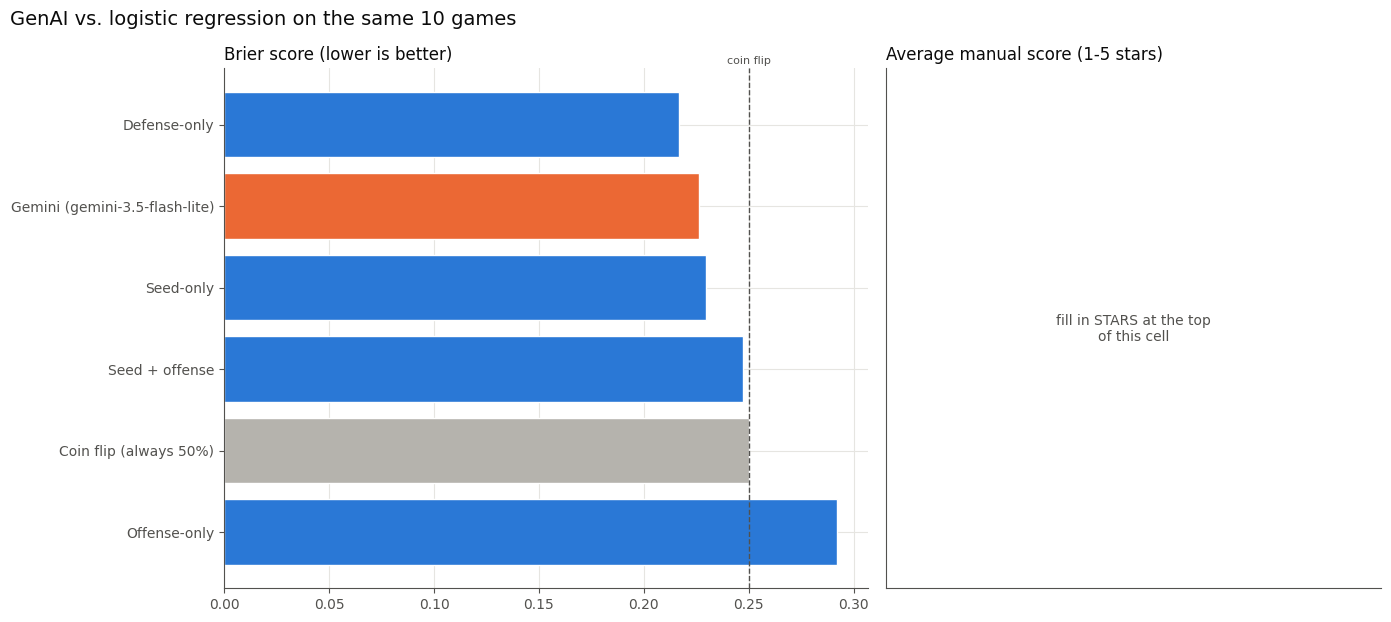

In [34]:
#@title GenAI comparison: results table and chart
# Paste your filled dict from the previous cell over this one. Leave it as {} to see
# the objective numbers before scoring.
STARS = {}

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"

y10 = games10.set_index("GameID").Label.astype(int)

def score_probs(p, y):
    p, y = np.asarray(p, float), np.asarray(y, int)
    ok = np.isfinite(p)
    if ok.sum() == 0:
        return np.nan, np.nan, 0
    return float(((p[ok] > 0.5) == (y[ok] == 1)).mean()), float(((p[ok] - y[ok]) ** 2).mean()), int(ok.sum())

# ---------- the project's own models, on the same ten games ----------
MODEL_COLS = {"Seed-only": "p_Seed", "Offense-only": "p_Offense", "Defense-only": "p_Defense"}
if "p_SeedOff" in games10.columns:
    MODEL_COLS["Seed + offense"] = "p_SeedOff"

rows = []
for name, col in MODEL_COLS.items():
    acc, brier, n = score_probs(games10.set_index("GameID")[col].reindex(y10.index), y10)
    rows.append({"Approach": name, "Type": "logistic regression",
                 "Accuracy (10)": acc, "Brier (10)": brier, "Replies used": n,
                 "Avg stars": np.nan})

# ---------- the LLMs ----------
for model, grp in genai_raw.groupby("model"):
    grp = grp.set_index("GameID").reindex(y10.index)
    acc, brier, n = score_probs(grp.prob_a, y10)
    stars = [STARS.get(c) for c in
             score_key.loc[score_key.model == model, "sheet_code"]] if STARS else []
    stars = [s for s in stars if isinstance(s, (int, float)) and s is not None]
    rows.append({"Approach": model,
                 "Type": grp.kind.dropna().iloc[0] if grp.kind.notna().any() else "LLM",
                 "Accuracy (10)": acc, "Brier (10)": brier, "Replies used": n,
                 "Avg stars": float(np.mean(stars)) if stars else np.nan})

rows.append({"Approach": "Coin flip (always 50%)", "Type": "baseline",
             "Accuracy (10)": np.nan, "Brier (10)": 0.25, "Replies used": len(y10),
             "Avg stars": np.nan})

comparison = pd.DataFrame(rows).sort_values("Brier (10)", na_position="last").reset_index(drop=True)

print(f"HEAD-TO-HEAD ON THE SAME {len(y10)} OUT-OF-SAMPLE GAMES (lower Brier is better)")
print(comparison.round(3).to_string(index=False, na_rep="-"))

# ---------- reminder: the models' real sample is far larger ----------
print(f"\nFor context, the same logistic models over all {len(preds):,} tournament games:")
for name, col in {"Seed-only": "p_Seed", "Offense-only": "p_Offense",
                  "Defense-only": "p_Defense"}.items():
    acc = float(((preds[col] > 0.5) == (preds.Label == 1)).mean())
    brier = float(((preds[col] - preds.Label) ** 2).mean())
    print(f"  {name:<14} accuracy {acc:.3f}   Brier {brier:.4f}")
print(f"\nTen games is a small sample: one flipped game moves accuracy by 10 points. "
      f"Treat the table above as illustrative and the {len(preds):,}-game numbers as the "
      f"project's real benchmark.")

# ---------- chart ----------
plot = comparison[comparison["Brier (10)"].notna()]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 0.55 * len(plot) + 3),
                               gridspec_kw={"width_ratios": [1.3, 1]})
fig.suptitle(f"GenAI vs. logistic regression on the same {len(y10)} games",
             fontsize=14, x=0.01, ha="left", color=INK)

colors = [BLUE if t == "logistic regression" else GRAY if t == "baseline" else ORANGE
          for t in plot.Type]
ax1.barh(plot.Approach, plot["Brier (10)"], color=colors, edgecolor="white")
ax1.axvline(0.25, color=MUTED, linestyle="--", linewidth=1)
ax1.text(0.25, -0.75, "coin flip", fontsize=8, color=MUTED, ha="center")
ax1.set_title("Brier score (lower is better)", loc="left", color=INK)
ax1.invert_yaxis()

stars = comparison[comparison["Avg stars"].notna()]
if len(stars):
    ax2.barh(stars.Approach, stars["Avg stars"], color=ORANGE, edgecolor="white")
    ax2.set_xlim(0, 5)
    ax2.set_title("Average manual score (1-5 stars)", loc="left", color=INK)
    ax2.invert_yaxis()
else:
    ax2.set_title("Average manual score (1-5 stars)", loc="left", color=INK)
    ax2.text(0.5, 0.5, "fill in STARS at the top\nof this cell", ha="center", va="center",
             color=MUTED, transform=ax2.transAxes)
    ax2.set_xticks([]); ax2.set_yticks([])

for ax in (ax1, ax2):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

comparison.to_csv("genai_comparison.csv", index=False)